In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

RANDOM_STATE = 42


## 1. Auditoría y preparación


In [2]:
df = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Al ejecutar `describe()` sobre el dataframe, se puede ver que el feature `TotalCharges` esta guardado como string, sin embargo, al analizar observar los datos con `head()` se puede observar que son valores numericos de tipo flotante, por lo tanto se va a transformar esta caracteristica

Dentro de la columna `TotalCharges` hay 11 valores vacíos (`' '`). Al revisar esas filas, **todas tienen `tenure = 0`**: son clientes nuevos que aún no han recibido su primera factura. Por eso se rellenan con 0 (el total facturado real), en lugar de eliminarlos, ya que también nos interesa predecir para clientes nuevos.

La corrección se aplica **solo a `TotalCharges`**, no a todo el DataFrame.

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['TotalCharges'].isna(), ['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isna().sum()

np.int64(0)

In [7]:
categorical_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

# Mostrar valores únicos por cada columna categórica
for col in categorical_cols:
    print(f"Columna: {col}")
    print(df[col].unique())  # Lista de valores únicos
    print("-" * 30)

print("\nConteo de valores únicos por columna categórica:")
print(df[categorical_cols].nunique())

Columna: customerID
<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
------------------------------
Columna: gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
------------------------------
Columna: Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
------------------------------
Columna: Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: MultipleLines
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
------------------------------
Columna: InternetService
<ArrowStringArray>
['DSL', 'Fiber opti

Customer ID no es feature, por lo que lo correcto es borrar este dato ya que no aporta informacion significativ al modelo para el aprendizaje.

In [8]:
df = df.drop('customerID', axis=1)

In [9]:
print('Duplicados sin customerID:', df.duplicated().sum())
df[df.duplicated(keep=False)][['tenure', 'Contract', 'MonthlyCharges', 'Churn']].describe(include='all')

Duplicados sin customerID: 22


,tenure,Contract,MonthlyCharges,Churn
count,42.0,42,42.000000,42
unique,NaN,1,NaN,2
top,NaN,Month-to-month,NaN,Yes
freq,NaN,42,NaN,24
mean,1.0,NaN,36.729762,NaN
std,0.0,NaN,22.367264,NaN
min,1.0,NaN,19.550000,NaN
25%,1.0,NaN,20.112500,NaN
50%,1.0,NaN,20.450000,NaN
75%,1.0,NaN,69.200000,NaN


Con `customerID` no había duplicados (cada ID es único), pero **sin él aparecen 22 filas duplicadas**. Todas corresponden a clientes con `tenure = 1` y perfiles muy simples, por lo que es plausible que sean **clientes distintos con el mismo perfil** (IDs diferentes). Se conservan para no alterar la distribución real.

In [10]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
df['Churn'].mean()  # debe ser ≈ 0.265

np.float64(0.2653698707936959)

In [11]:
df['Churn'].value_counts(normalize=True).round(3)

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

In [12]:
df.Churn.unique()

array([0, 1])

El dataset está desbalanceado (73.5 % No / 26.5 % Sí). Un modelo que prediga que nadie abandona tendría un accuracy de 73.5 % sin detectar ningún churn, por lo que se usará **F1-score** como métrica principal.

In [13]:
pd.crosstab(df['InternetService'], df['OnlineSecurity'], margins=True)

OnlineSecurity,No,No internet service,Yes,All
InternetService,,,,
DSL,1241,0,1180,2421
Fiber optic,2257,0,839,3096
No,0,1526,0,1526
All,3498,1526,2019,7043


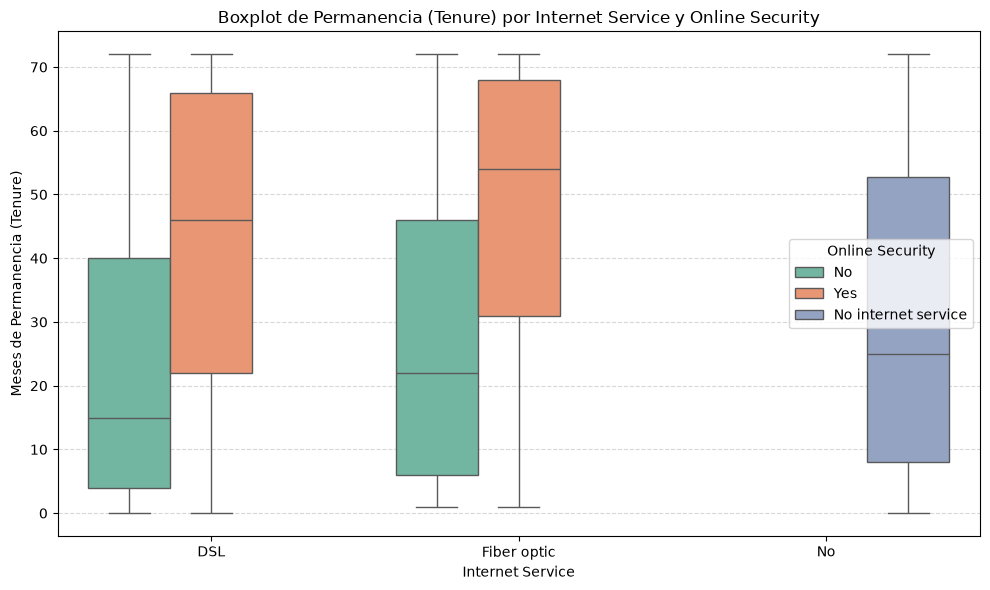

In [14]:

# Boxplot para analizar Tenure (permanencia) respecto a estas variables
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='InternetService', y='tenure', hue='OnlineSecurity', palette='Set2')
plt.title('Boxplot de Permanencia (Tenure) por Internet Service y Online Security')
plt.xlabel('Internet Service')
plt.ylabel('Meses de Permanencia (Tenure)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Online Security')
plt.tight_layout()
plt.show()

Como se puede ver en la grafica, existe colinealidad entre OnlineSecurity e InternetService. y la clase de No Internet Service no es linealmente independiente de la clase NO. Por lo que es justificado transformar esta ultima clase a No, para no tener informacion redundante.

In [15]:
categorical_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

# Mostrar valores únicos por cada columna categórica
for col in categorical_cols:
    vals= df[col].unique()
    if 'No internet service' in vals:
      df.replace({'No internet service': 'No'}, inplace=True)
    print(f"Columna: {col}")
    print(df[col].unique())  # Lista de valores únicos
    print("-" * 30)


Columna: gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
------------------------------
Columna: Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
------------------------------
Columna: Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: MultipleLines
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
------------------------------
Columna: InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
------------------------------
Columna: OnlineSecurity
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: OnlineBackup
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
------------------------------
Columna: DeviceProtection
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
----------------------

In [16]:
categorical_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

# Mostrar valores únicos por cada columna categórica
for col in categorical_cols:
    vals= df[col].unique()
    if 'No phone service' in vals:
      df.replace({'No phone service': 'No'}, inplace=True)
    print(f"Columna: {col}")
    print(df[col].unique())  # Lista de valores únicos
    print("-" * 30)

Columna: gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
------------------------------
Columna: Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
------------------------------
Columna: Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: MultipleLines
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
------------------------------
Columna: OnlineSecurity
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: OnlineBackup
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
------------------------------
Columna: DeviceProtection
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
------------------------------
Columna: Te

### 1.1 EDA: ¿qué perfiles abandonan más?

Se calcula la **tasa de churn por segmento** (proporción de clientes que abandonan dentro de cada categoría). La línea roja es la tasa global (26.5 %): las barras por encima son segmentos de riesgo.

> El EDA es descriptivo: no ajusta ningún parámetro del modelo, por lo que no genera data leakage. Los grupos de `tenure` se crean solo para graficar; **no se agregan al DataFrame**.

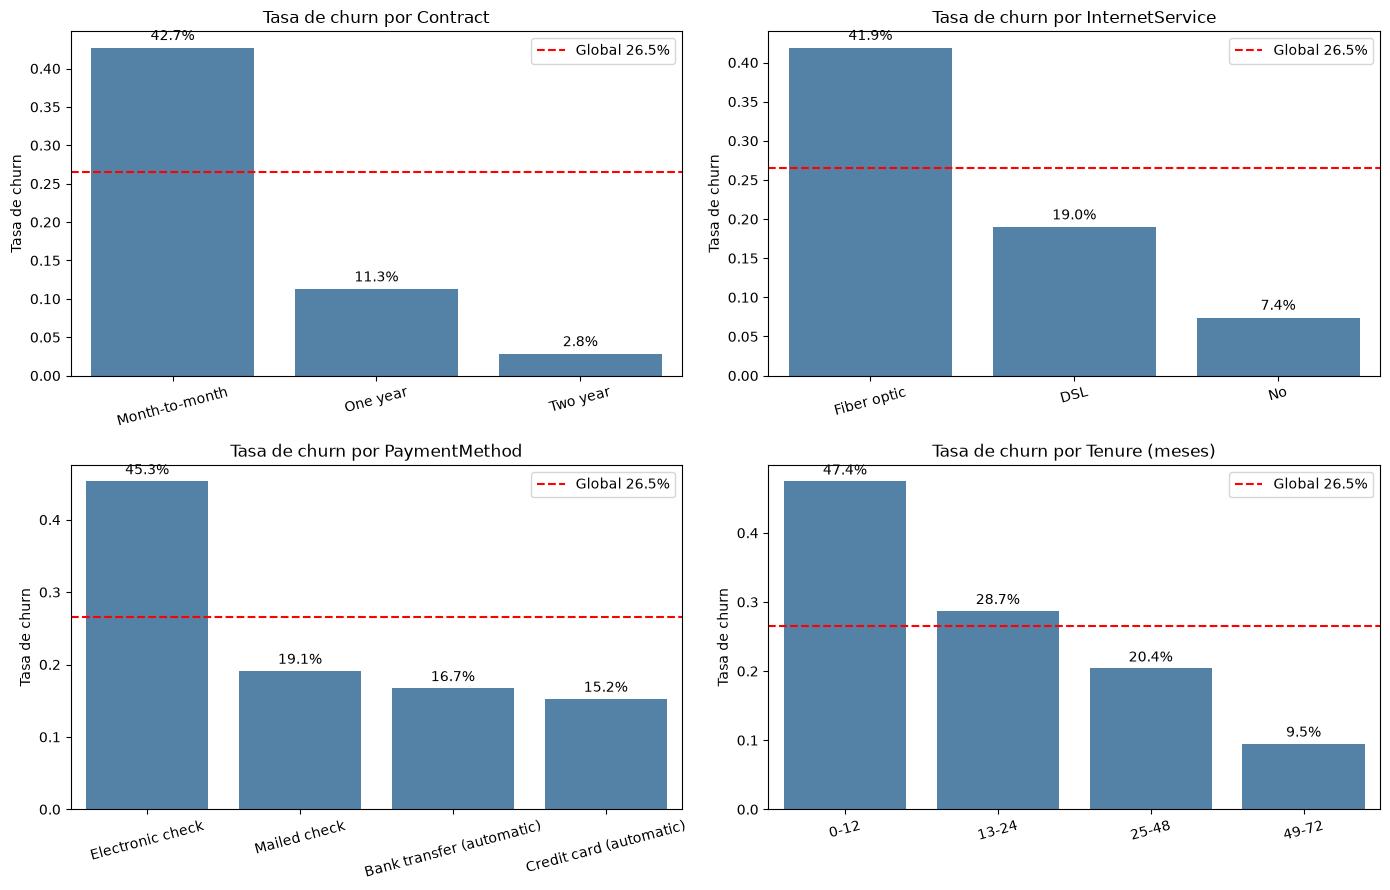

In [17]:
churn_global = df['Churn'].mean()
tenure_group = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                      labels=['0-12', '13-24', '25-48', '49-72'])

segmentos = {
    'Contract': df['Contract'],
    'InternetService': df['InternetService'],
    'PaymentMethod': df['PaymentMethod'],
    'Tenure (meses)': tenure_group,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, serie) in zip(axes.ravel(), segmentos.items()):
    tasa = df['Churn'].groupby(serie, observed=True).mean().sort_values(ascending=False)
    sns.barplot(x=tasa.index.astype(str), y=tasa.values, ax=ax, color='steelblue')
    ax.axhline(churn_global, color='red', linestyle='--', label=f'Global {churn_global:.1%}')
    for i, v in enumerate(tasa.values):
        ax.text(i, v + 0.01, f'{v:.1%}', ha='center')
    ax.set_title(f'Tasa de churn por {name}')
    ax.set_xlabel('')
    ax.set_ylabel('Tasa de churn')
    ax.tick_params(axis='x', rotation=15)
    ax.legend()
plt.tight_layout()
plt.show()

**Observaciones:**

- **Contrato:** mes a mes tiene 42.7 % de churn frente a 11.3 % (1 año) y 2.8 % (2 años). Es la variable que más separa las clases.
- **Antigüedad:** los clientes del primer año abandonan un 47.4 %; a partir de 4 años, solo un 9.5 %. El riesgo se concentra al inicio de la relación.
- **Internet:** fibra óptica tiene 41.9 % de churn, más del doble que DSL (19.0 %), a pesar de ser el servicio premium.
- **Método de pago:** cheque electrónico tiene 45.3 %, unas 3 veces más que los pagos automáticos (~15–17 %).

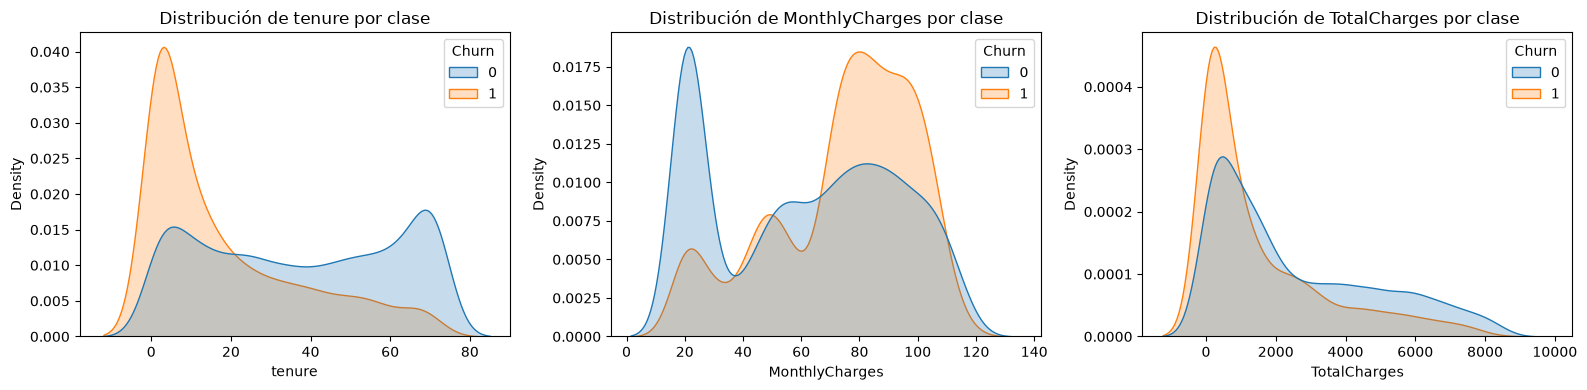

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.425,1679.525
1,10.0,79.650,703.550


In [18]:
num_vars = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_vars):
    sns.kdeplot(data=df, x=col, hue='Churn', common_norm=False, fill=True, ax=ax)
    ax.set_title(f'Distribución de {col} por clase')
plt.tight_layout()
plt.show()

df.groupby('Churn')[num_vars].median()

**Observaciones:**

- Los clientes que abandonan tienen una **mediana de 10 meses** de antigüedad frente a 38 de los que se quedan.
- Pagan **más por mes** (mediana 79.7 vs 64.4): coherente con que la fibra óptica concentre el churn.
- `TotalCharges` es menor en los que abandonan, pero porque llevan menos tiempo: es casi `tenure × MonthlyCharges`.

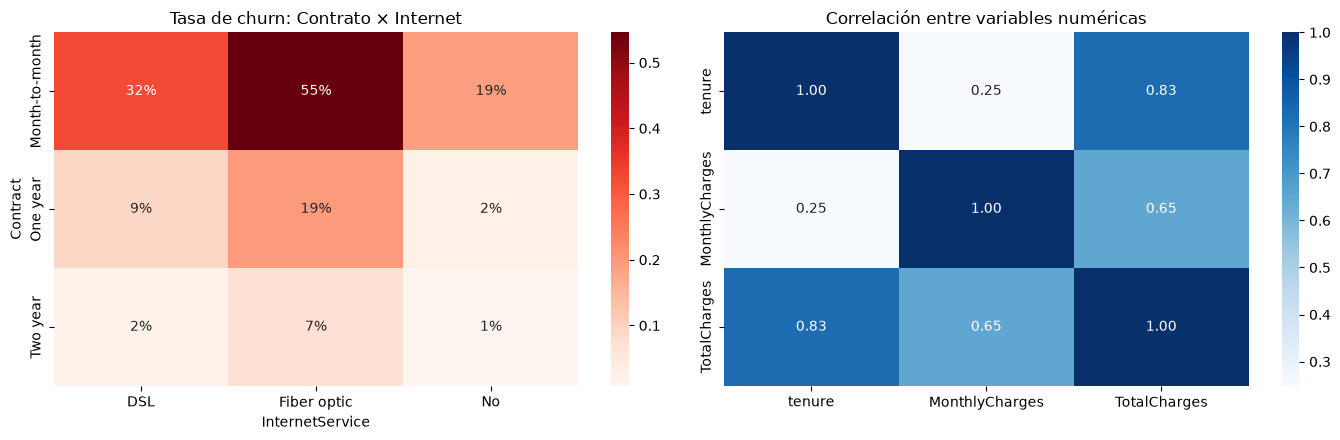

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cruce = pd.crosstab(df['Contract'], df['InternetService'], values=df['Churn'], aggfunc='mean')
sns.heatmap(cruce, annot=True, fmt='.0%', cmap='Reds', ax=axes[0])
axes[0].set_title('Tasa de churn: Contrato × Internet')
sns.heatmap(df[num_vars].corr(), annot=True, fmt='.2f', cmap='Blues', ax=axes[1])
axes[1].set_title('Correlación entre variables numéricas')
plt.tight_layout()
plt.show()

**Observaciones:**

- La combinación **mes a mes + fibra óptica** llega a **55 % de churn**: es el segmento de mayor riesgo. Con contrato de 2 años, la fibra baja a 7 %.
- `TotalCharges` está muy correlacionada con `tenure` (0.83) y bastante con `MonthlyCharges` (0.65): aporta información redundante. No se elimina (los árboles no se ven afectados), pero hay que tenerlo en cuenta al interpretar coeficientes y SHAP, porque la importancia se repartirá entre variables correlacionadas.
- `gender` no muestra diferencia (26.9 % vs 26.2 %): probablemente no aporte al modelo.

### 1.2 Hallazgos clave del EDA

1. **Desbalance 73.5 / 26.5:** accuracy no es una métrica válida; se usa F1 y se ponderan las clases.
2. **`TotalCharges` venía como texto** con 11 vacíos, todos de clientes con `tenure = 0`; se rellenan con 0.
3. **El riesgo se concentra en clientes nuevos, con contrato mes a mes, fibra óptica y pago con cheque electrónico.** Son relaciones predictivas, **no causales**: por ejemplo, el cheque electrónico podría ser un indicador de otro perfil de cliente, no la causa del abandono.
4. **Categorías redundantes** ("No internet service", "No phone service") duplicaban información de `InternetService` y `PhoneService`; se unificaron a "No".
5. **Variables numéricas correlacionadas** (`TotalCharges` ≈ `tenure × MonthlyCharges`): afectará a la interpretación en la Parte 4.

## 2. Train/Test y pipeline
Separe objetivo/predictores. Analice `customerID`. Realice un split estratificado.

Construya un `ColumnTransformer` con tratamiento numérico y categórico y encapsúlelo en un `Pipeline`.

**Explique:** ¿cómo evita su procedimiento el data leakage?


In [20]:
columns = list(df.columns)

cat_columns =[]
num_columns = []

for i in columns:
  if len(df[i].unique())>6:
    num_columns.append(i)
  else:
    cat_columns.append(i)
cat_columns.remove('Churn')

print('categorical_features:', cat_columns)
print('Numerical Features:', num_columns)

categorical_features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical Features: ['tenure', 'MonthlyCharges', 'TotalCharges']


Se usa un único split **80/20 estratificado**. No se separa un conjunto de validación porque la selección de modelos y la optimización se harán con **validación cruzada estratificada** sobre el 80 % de entrenamiento. El conjunto de test queda aislado hasta la evaluación final.

In [21]:
X = df.drop(columns='Churn')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [22]:
print('Train:', X_train.shape, '| churn rate:', round(y_train.mean(), 3))
print('Test: ', X_test.shape, '| churn rate:', round(y_test.mean(), 3))

Train: (5634, 19) | churn rate: 0.265
Test:  (1409, 19) | churn rate: 0.265


In [23]:
def pipeline_builder(num_strategy, num_scaler, cat_strategy, cat_encoder, selected_model):
  num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy=num_strategy)),
        ('scaler', num_scaler),
    ])
  cat_pipeline = Pipeline([
      ('imputer', SimpleImputer(strategy=cat_strategy)),
      ('encoder', cat_encoder)]
  )
  linked_preprocess = ColumnTransformer([
      ('num', num_pipeline, num_columns),
      ('cat', cat_pipeline, cat_columns)
  ])
  final_pipeline = Pipeline([
      ('preprocess', linked_preprocess),
      ('model_instance', selected_model)
  ])
  return final_pipeline

In [24]:
# Verificación: el preprocesador se ajusta SOLO con X_train
pipe = pipeline_builder('median', StandardScaler(), 'most_frequent',
                        OneHotEncoder(handle_unknown='ignore', drop='if_binary'),
                        LogisticRegression(max_iter=1000))
Xt = pipe.named_steps['preprocess'].fit_transform(X_train)
print(Xt.shape)
pipe.named_steps['preprocess'].get_feature_names_out()

(5634, 26)


array(['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges',
       'cat__gender_Male', 'cat__SeniorCitizen_1', 'cat__Partner_Yes',
       'cat__Dependents_Yes', 'cat__PhoneService_Yes',
       'cat__MultipleLines_Yes', 'cat__InternetService_DSL',
       'cat__InternetService_Fiber optic', 'cat__InternetService_No',
       'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_Yes',
       'cat__DeviceProtection_Yes', 'cat__TechSupport_Yes',
       'cat__StreamingTV_Yes', 'cat__StreamingMovies_Yes',
       'cat__Contract_Month-to-month', 'cat__Contract_One year',
       'cat__Contract_Two year', 'cat__PaperlessBilling_Yes',
       'cat__PaymentMethod_Bank transfer (automatic)',
       'cat__PaymentMethod_Credit card (automatic)',
       'cat__PaymentMethod_Electronic check',
       'cat__PaymentMethod_Mailed check'], dtype=object)

## 3. Modelado y comparación
Compare al menos dos modelos bajo los mismos folds. Puede usar Logistic Regression y Random Forest u otros modelos justificados.

Reporte Precision, Recall, F1 y ROC-AUC. Interprete especialmente los falsos negativos: clientes que realmente abandonan pero el modelo no detecta.


### 3.1 Protocolo de validación

Se define **un único** `StratifiedKFold` de 5 particiones que se reutiliza en todo el proyecto (comparación de modelos, optimización y multiobjetivo). Así todos los modelos se evalúan exactamente sobre los mismos datos y las diferencias se deben al modelo, no al azar del particionado.

- **Estratificado:** cada fold conserva el 26.5 % de churn.
- **Métrica principal:** F1 (clase churn = 1). Se reportan además Accuracy, Precision, Recall y ROC-AUC.
- El preprocesamiento está dentro del `Pipeline`, por lo que en cada fold el imputer, el scaler y el one-hot se ajustan **solo con los datos de entrenamiento de ese fold** → sin data leakage.

In [25]:
from sklearn.model_selection import cross_val_predict
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

### 3.2 Modelos candidatos

| Modelo | Rol en el proyecto | Tratamiento del desbalance |
|---|---|---|
| Logistic Regression | Baseline lineal e interpretable | `class_weight='balanced'` |
| Random Forest | Requerido para comparar su feature importance con SHAP/LIME | `class_weight='balanced'` |
| XGBoost | Boosting, suele ser el más fuerte en datos tabulares | `scale_pos_weight = nº negativos / nº positivos` |

Los tres corrigen el desbalance de la misma forma conceptual: dar más peso a los errores sobre la clase churn.

In [26]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def make_pipe(model):
    return pipeline_builder('median', StandardScaler(), 'most_frequent',
                            OneHotEncoder(handle_unknown='ignore', drop='if_binary'), model)

models = {
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced',
                                                        random_state=RANDOM_STATE)),
    'Random Forest': make_pipe(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                      n_jobs=-1, random_state=RANDOM_STATE)),
    'XGBoost': make_pipe(XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                       n_jobs=-1, random_state=RANDOM_STATE)),
}
print('scale_pos_weight =', round(scale_pos_weight, 2))

scale_pos_weight = 2.77


In [27]:
cv_results = {}
for name, pipe in models.items():
    cv_results[name] = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)

rows = []
for name, res in cv_results.items():
    row = {'Modelo': name}
    for m in scoring:
        s = res[f'test_{m}']
        row[m] = f'{s.mean():.3f} ± {s.std():.3f}'
    row['fit_time (s)'] = round(res['fit_time'].mean(), 2)
    rows.append(row)

results_df = pd.DataFrame(rows).set_index('Modelo')
results_df

,accuracy,precision,recall,f1,roc_auc,fit_time (s)
Modelo,,,,,,
Logistic Regression,0.749 ± 0.014,0.518 ± 0.017,0.803 ± 0.037,0.629 ± 0.021,0.846 ± 0.012,0.08
Random Forest,0.779 ± 0.012,0.573 ± 0.021,0.659 ± 0.036,0.613 ± 0.026,0.827 ± 0.011,0.72
XGBoost,0.765 ± 0.007,0.549 ± 0.011,0.649 ± 0.017,0.595 ± 0.013,0.821 ± 0.007,0.39


### 3.3 Matrices de confusión (predicciones de validación cruzada)

Se usan predicciones *out-of-fold* (`cross_val_predict`): cada cliente del train es predicho por un modelo que no lo vio al entrenar. **El test sigue sin tocarse.**

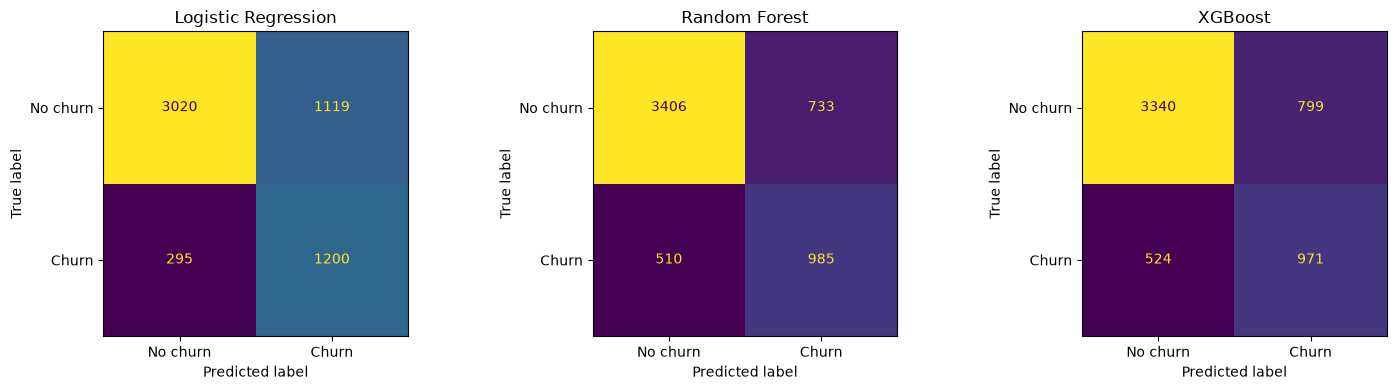

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, models.items()):
    y_pred = cross_val_predict(pipe, X_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, ax=ax, colorbar=False,
                                            display_labels=['No churn', 'Churn'])
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 3.4 Interpretación y modelo candidato

**Resultados (CV 5-fold sobre train, media ± desviación):**

- **Logistic Regression** obtiene el mejor F1 (0.629) y el mejor ROC-AUC (0.846), y es el más rápido.
- **Random Forest** (0.613) y **XGBoost** (0.595) quedan por debajo **con hiperparámetros por defecto**: los árboles del RF crecen sin límite de profundidad y tienden a memorizar el train, por lo que su optimización (Parte 2) tiene mucho margen.
- La diferencia LR vs RF en F1 (0.016) es menor que la desviación estándar del RF (0.026): **todavía no es una diferencia concluyente**.

**Falsos negativos (clientes que se van y el modelo no detecta), sobre 1495 churners del train:**

| Modelo | Detectados (TP) | No detectados (FN) | Falsas alarmas (FP) |
|---|---|---|---|
| Logistic Regression | 1200 | **295** | 1119 |
| Random Forest | 985 | 510 | 733 |
| XGBoost | 971 | 524 | 799 |

La Regresión Logística detecta ~215 churners más que el RF, a cambio de ~390 falsas alarmas adicionales. Si una campaña de retención cuesta mucho menos que perder un cliente, ese intercambio es favorable al negocio.

**Decisión:**
- **Modelo baseline de referencia:** Logistic Regression (mejor F1 actual, interpretable, inferencia casi instantánea).
- **Modelo a optimizar en la Parte 2:** Random Forest. Motivos: (1) la Parte 4 exige comparar con su feature importance, por lo que optimizar y explicar el mismo modelo es más coherente; (2) tiene hiperparámetros con impacto real (profundidad, tamaño de hojas, nº de árboles), lo que hace la comparación de optimizadores informativa; (3) su latencia depende de `n_estimators`, lo que da un compromiso real para la Parte 3.
- El objetivo de la optimización es **superar el baseline de F1 = 0.629**. Si no lo supera, se reportará honestamente y el modelo final será el que mejor F1 tenga en CV.

## 4. Optimización de hiperparámetros (Random Forest)

### 4.0 ¿Por qué optimizar? Evidencia de sobreajuste

Se compara el F1 en los datos de entrenamiento de cada fold con el F1 en el fold de validación. Una brecha grande indica que el modelo memoriza el train en lugar de generalizar.

In [29]:
res_rf = cross_validate(models['Random Forest'], X_train, y_train, cv=cv, scoring='f1',
                        return_train_score=True)
print(f"RF por defecto -> F1 train: {res_rf['train_score'].mean():.3f} | "
      f"F1 validación: {res_rf['test_score'].mean():.3f}")

RF por defecto -> F1 train: 0.992 | F1 validación: 0.613


### 4.1 Protocolo común y espacio de búsqueda

Las tres estrategias comparten: **mismo modelo base** (Random Forest con `class_weight='balanced'`), **mismo `cv`** (StratifiedKFold 5), **misma métrica** (F1) y **mismo presupuesto: 48 configuraciones** (= tamaño de la rejilla de Grid Search). El test no se usa.

| Hiperparámetro | Qué controla | Grid Search (48 combinaciones) | Random Search / TPE |
|---|---|---|---|
| `n_estimators` | Nº de árboles (estabilidad vs tiempo) | {100, 300} | entero en [100, 500] |
| `max_depth` | Profundidad máxima (complejidad, sobreajuste) | {5, 8, 12, 16} | entero en [3, 20] |
| `min_samples_leaf` | Mínimo de clientes por hoja (suaviza el modelo) | {1, 5, 10} | entero en [1, 30] |
| `max_features` | Fracción de variables por división (diversidad entre árboles) | {0.2, 0.5} | real en [0.1, 0.8] |

El espacio continuo de Random/TPE **contiene** a la rejilla de Grid: cualquier configuración de Grid podría ser encontrada por los otros dos.

In [30]:
import time
import optuna
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_CONFIGS = 48
P = 'model_instance__'  # prefijo para llegar al modelo dentro del Pipeline

def make_rf(**params):
    return make_pipe(RandomForestClassifier(**params, class_weight='balanced', n_jobs=-1,
                                            random_state=RANDOM_STATE))

param_grid = {
    P + 'n_estimators': [100, 300],
    P + 'max_depth': [5, 8, 12, 16],
    P + 'min_samples_leaf': [1, 5, 10],
    P + 'max_features': [0.2, 0.5],
}
param_dist = {
    P + 'n_estimators': randint(100, 501),
    P + 'max_depth': randint(3, 21),
    P + 'min_samples_leaf': randint(1, 31),
    P + 'max_features': uniform(0.1, 0.7),  # uniforme en [0.1, 0.8]
}

### 4.2 Grid Search

**Cómo funciona:** evalúa **todas** las combinaciones de una rejilla de valores fijada a mano. Es exhaustivo y reproducible, pero el costo crece multiplicativamente con cada hiperparámetro y solo explora los valores que el analista eligió.

In [31]:
t0 = time.perf_counter()
grid = GridSearchCV(make_rf(), param_grid, cv=cv, scoring='f1')
grid.fit(X_train, y_train)
t_grid = time.perf_counter() - t0
print(f'Configuraciones: {len(grid.cv_results_["params"])} | Tiempo: {t_grid:.1f} s | Mejor F1: {grid.best_score_:.3f}')
grid.best_params_

Configuraciones: 48 | Tiempo: 132.2 s | Mejor F1: 0.637


{'model_instance__max_depth': 16,
 'model_instance__max_features': 0.2,
 'model_instance__min_samples_leaf': 5,
 'model_instance__n_estimators': 100}

### 4.3 Random Search

**Cómo funciona:** muestrea configuraciones **al azar** de distribuciones definidas sobre rangos continuos. Con el mismo presupuesto prueba más valores distintos de cada hiperparámetro que Grid, lo que ayuda cuando solo unos pocos hiperparámetros importan. No aprende de los resultados anteriores.

In [32]:
t0 = time.perf_counter()
rand = RandomizedSearchCV(make_rf(), param_dist, n_iter=N_CONFIGS, cv=cv, scoring='f1',
                          random_state=RANDOM_STATE)
rand.fit(X_train, y_train)
t_rand = time.perf_counter() - t0
print(f'Configuraciones: {N_CONFIGS} | Tiempo: {t_rand:.1f} s | Mejor F1: {rand.best_score_:.3f}')
rand.best_params_

Configuraciones: 48 | Tiempo: 196.5 s | Mejor F1: 0.635


{'model_instance__max_depth': 13,
 'model_instance__max_features': np.float64(0.2391896828621636),
 'model_instance__min_samples_leaf': 8,
 'model_instance__n_estimators': 262}

### 4.4 Optimización bayesiana (TPE con Optuna)

**Cómo funciona:** el *Tree-structured Parzen Estimator* separa las configuraciones ya evaluadas en "buenas" (mejor F1) y "malas", estima la densidad de cada grupo y propone la siguiente configuración donde la probabilidad de ser buena es alta en relación con la de ser mala. **Aprende de los resultados anteriores**, por lo que concentra el presupuesto en las zonas prometedoras. Las primeras pruebas son aleatorias (fase de exploración).

In [33]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 30),
        'max_features': trial.suggest_float('max_features', 0.1, 0.8),
    }
    scores = cross_val_score(make_rf(**params), X_train, y_train, cv=cv, scoring='f1')
    return scores.mean()

t0 = time.perf_counter()
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_CONFIGS)
t_tpe = time.perf_counter() - t0
print(f'Configuraciones: {len(study.trials)} | Tiempo: {t_tpe:.1f} s | Mejor F1: {study.best_value:.3f}')
study.best_params

Configuraciones: 48 | Tiempo: 159.0 s | Mejor F1: 0.639


{'n_estimators': 200,
 'max_depth': 19,
 'min_samples_leaf': 5,
 'max_features': 0.22614510881624672}

### 4.5 Comparación de estrategias

La mejor configuración de cada estrategia se re-evalúa con el mismo `cv` y todas las métricas. Se incluye el F1 en train para verificar que la optimización redujo el sobreajuste, y la Regresión Logística como referencia.

In [34]:
best_params = {
    'Grid Search': {k.replace(P, ''): v for k, v in grid.best_params_.items()},
    'Random Search': {k.replace(P, ''): v for k, v in rand.best_params_.items()},
    'TPE (Optuna)': study.best_params,
}
tiempos = {'Grid Search': t_grid, 'Random Search': t_rand, 'TPE (Optuna)': t_tpe}

rows = []
for name, params in best_params.items():
    res = cross_validate(make_rf(**params), X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True)
    rows.append({'Estrategia': name, 'Configuraciones': N_CONFIGS, 'Tiempo (s)': round(tiempos[name], 1),
                 'F1': res['test_f1'].mean(), 'F1 std': res['test_f1'].std(),
                 'F1 train': res['train_f1'].mean(),
                 'Precision': res['test_precision'].mean(), 'Recall': res['test_recall'].mean(),
                 'ROC-AUC': res['test_roc_auc'].mean(), 'Accuracy': res['test_accuracy'].mean(),
                 'Parámetros': {k: float(round(v, 3)) if isinstance(v, float) else v for k, v in params.items()}})

lr = cv_results['Logistic Regression']
rows.append({'Estrategia': 'Baseline: Logistic Regression', 'Configuraciones': 1, 'Tiempo (s)': None,
             'F1': lr['test_f1'].mean(), 'F1 std': lr['test_f1'].std(), 'F1 train': None,
             'Precision': lr['test_precision'].mean(), 'Recall': lr['test_recall'].mean(),
             'ROC-AUC': lr['test_roc_auc'].mean(), 'Accuracy': lr['test_accuracy'].mean(), 'Parámetros': '-'})

opt_df = pd.DataFrame(rows).set_index('Estrategia')
opt_df.round(3)

,Configuraciones,Tiempo (s),F1,F1 std,F1 train,Precision,Recall,ROC-AUC,Accuracy,Parámetros
Estrategia,,,,,,,,,,
Grid Search,48,132.2,0.637,0.018,0.745,0.545,0.767,0.844,0.768,"{'max_depth': 16, 'max_features': 0.2, 'min_sa..."
Random Search,48,196.5,0.635,0.013,0.713,0.538,0.776,0.846,0.764,"{'max_depth': 13, 'max_features': 0.239, 'min_..."
TPE (Optuna),48,159.0,0.639,0.018,0.746,0.546,0.771,0.845,0.769,"{'n_estimators': 200, 'max_depth': 19, 'min_sa..."
Baseline: Logistic Regression,1,NaN,0.629,0.021,NaN,0.518,0.803,0.846,0.749,-


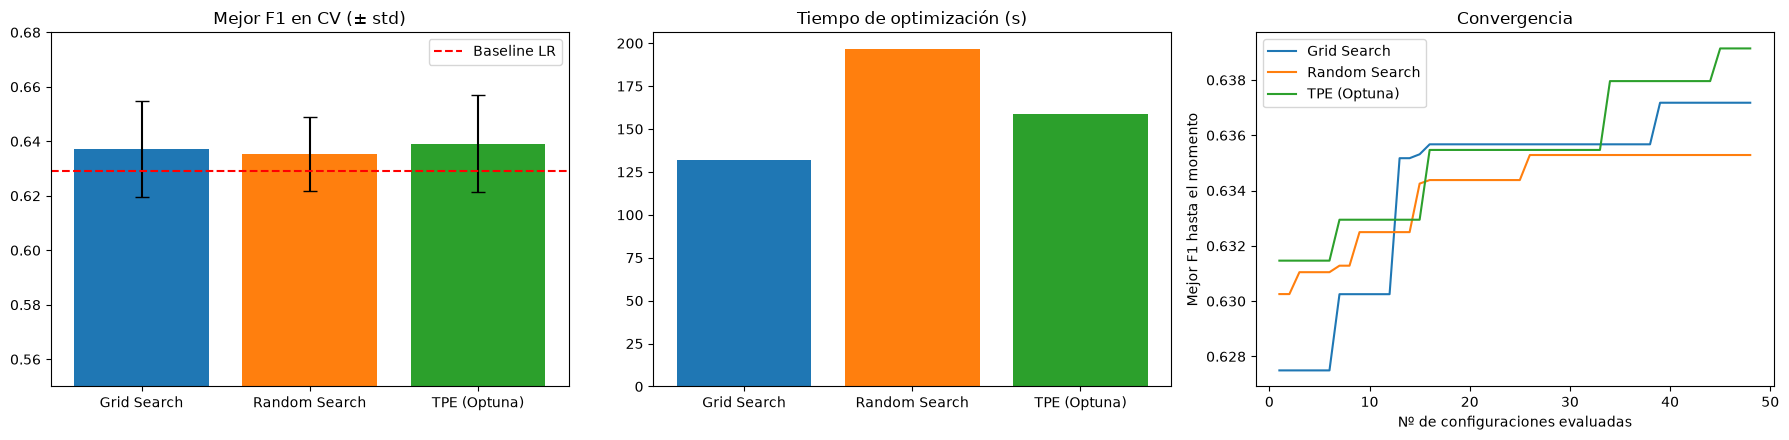

In [35]:
historias = {
    'Grid Search': grid.cv_results_['mean_test_score'],
    'Random Search': rand.cv_results_['mean_test_score'],
    'TPE (Optuna)': np.array([t.value for t in study.trials]),
}
estrategias = list(best_params)
colores = ['tab:blue', 'tab:orange', 'tab:green']

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(estrategias, opt_df.loc[estrategias, 'F1'], yerr=opt_df.loc[estrategias, 'F1 std'],
            color=colores, capsize=5)
axes[0].axhline(opt_df.loc['Baseline: Logistic Regression', 'F1'], color='red', linestyle='--',
                label='Baseline LR')
axes[0].set_ylim(0.55, 0.68)
axes[0].set_title('Mejor F1 en CV (± std)')
axes[0].legend()

axes[1].bar(estrategias, opt_df.loc[estrategias, 'Tiempo (s)'], color=colores)
axes[1].set_title('Tiempo de optimización (s)')

for (name, h), c in zip(historias.items(), colores):
    axes[2].plot(range(1, len(h) + 1), np.maximum.accumulate(h), label=name, color=c)
axes[2].set_xlabel('Nº de configuraciones evaluadas')
axes[2].set_ylabel('Mejor F1 hasta el momento')
axes[2].set_title('Convergencia')
axes[2].legend()
plt.tight_layout()
plt.show()

### 4.6 Análisis de resultados

**1. La optimización corrigió el sobreajuste.** El RF por defecto tenía F1 train = 0.992 vs validación = 0.613 (memorizaba). Optimizado: train ≈ 0.75 vs validación ≈ 0.64. La brecha se redujo de 0.38 a ~0.11 y el F1 de validación subió ~0.025.

**2. Las tres estrategias empatan en desempeño.** Los mejores F1 (0.635–0.639) difieren en ≤ 0.004, muy por debajo de la desviación estándar entre folds (~0.015–0.018). Con este presupuesto, ninguna estrategia es estadísticamente superior.

**3. Las tres coinciden en lo que importa:** `min_samples_leaf` entre 5 y 8 y `max_features` ≈ 0.2–0.24. Es decir, el RF mejora con hojas que exigen varios clientes y con árboles que ven pocas variables por división (más diversidad). `max_depth` (13–19) y `n_estimators` (100–262) varían sin cambiar el resultado: son hiperparámetros poco sensibles en este problema. Que tres métodos distintos lleguen a la misma zona da **robustez** a la conclusión.

**4. Tiempo.** Grid fue el más rápido (131 s), pero no por ser mejor método: su rejilla solo tenía `n_estimators` ∈ {100, 300}, mientras Random/TPE muestrearon hasta 500 árboles. El tiempo está dominado por el costo de entrenar cada configuración; la sobrecarga propia de TPE es despreciable. **Comparar tiempos exige mirar qué configuraciones evaluó cada uno.**

**5. Convergencia.** TPE alcanzó el mejor valor final y mantuvo una curva en ascenso al final (sigue aprendiendo), Random se estancó desde la configuración ~26 y Grid depende del orden de la rejilla (su salto en ~13 es casualidad del orden, no aprendizaje).

**6. RF optimizado vs Regresión Logística.** El RF optimizado (F1 0.639) supera al baseline (0.629) en 0.010, pero esa diferencia también está dentro de la desviación estándar: **es un empate técnico**. El RF ofrece algo más de precision (0.546 vs 0.518) y la LR algo más de recall (0.803 vs 0.771).

| | Ventajas | Limitaciones |
|---|---|---|
| **Grid Search** | Exhaustivo dentro de la rejilla, reproducible, fácil de explicar | Explosión combinatoria; solo prueba valores elegidos a mano |
| **Random Search** | Explora más valores por hiperparámetro con el mismo presupuesto; paralelizable | No aprende de resultados previos; puede estancarse |
| **TPE (Optuna)** | Aprende y concentra el presupuesto en zonas prometedoras; escala a espacios grandes | Secuencial; con presupuestos pequeños su ventaja es modesta |

**Estrategia seleccionada: TPE (Optuna).** No por su F1 (empate), sino porque (a) obtuvo el mejor valor y seguía mejorando, por lo que escala mejor si se amplía el presupuesto o el espacio; (b) maneja espacios continuos sin rejillas manuales; y (c) Optuna es el mismo marco que usaremos para la optimización multiobjetivo con NSGA-II (Parte 3), lo que mantiene el protocolo consistente.

**Configuración seleccionada (RF-TPE):** `n_estimators=200, max_depth=19, min_samples_leaf=5, max_features≈0.226`. La decisión final entre RF y LR se tomará tras la Parte 3, considerando también latencia y explicabilidad.

In [36]:
import os
os.makedirs('artifacts', exist_ok=True)
opt_df.to_csv('artifacts/optimization_results.csv')
pd.DataFrame({k: pd.Series(v) for k, v in historias.items()}).to_csv('artifacts/optimization_history.csv',
                                                                    index_label='config')

## 5. Optimización multiobjetivo (NSGA-II)

### 5.1 Problema de negocio

La herramienta indica al equipo de marketing **a qué clientes ofrecer una promoción de retención**. Hay dos objetivos en conflicto:

- **Recall:** encontrar a la mayor cantidad posible de clientes que realmente se van (cada churner no detectado es un cliente perdido).
- **Precision:** que los clientes contactados realmente estuvieran por irse (cada falsa alarma es una promoción regalada a quien se iba a quedar).

Subir uno baja el otro: para detectar más churners hay que contactar a más gente, y entre ellos habrá más falsas alarmas. No existe una única solución óptima, sino un **conjunto de compromisos** (frente de Pareto).

### 5.2 Formulación matemática

Variables de decisión: $\theta = (n\_estimators,\ max\_depth,\ min\_samples\_leaf,\ max\_features,\ \tau)$, donde $\tau$ es el **umbral de decisión**: un cliente se marca como churn si $\hat p(\text{churn}) \geq \tau$.

$$\max_{\theta \in \Theta} \; f_1(\theta) = \text{Recall}_{CV}(\theta) = \frac{TP}{TP + FN}$$

$$\max_{\theta \in \Theta} \; f_2(\theta) = \text{Precision}_{CV}(\theta) = \frac{TP}{TP + FP}$$

con $\Theta$: `n_estimators` ∈ [100, 500], `max_depth` ∈ [3, 20], `min_samples_leaf` ∈ [1, 30], `max_features` ∈ [0.1, 0.8] (mismo espacio de la Parte 2) y $\tau$ ∈ [0.2, 0.8].

Ambas métricas se calculan con predicciones *out-of-fold* del mismo `cv` de 5 folds: **el test no se usa**.

**Dominancia:** una solución A domina a B si es al menos igual de buena en ambos objetivos y estrictamente mejor en uno. El frente de Pareto es el conjunto de soluciones **no dominadas**.

### 5.3 NSGA-II

Algoritmo genético: parte de una población de configuraciones, las ordena por **niveles de dominancia** (primero las no dominadas) y, dentro de cada nivel, prefiere las más aisladas (**crowding distance**) para cubrir todo el frente. Las mejores se cruzan y mutan para generar la siguiente generación. Se usan 80 evaluaciones (población 20 → 4 generaciones).

In [37]:
import json
N_TRIALS_MO = 80
oof_store = {}  # probabilidades out-of-fold de cada trial (para el análisis de negocio)

def mo_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 30),
        'max_features': trial.suggest_float('max_features', 0.1, 0.8),
    }
    threshold = trial.suggest_float('threshold', 0.2, 0.8)
    proba = cross_val_predict(make_rf(**params), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    oof_store[trial.number] = proba
    y_pred = (proba >= threshold).astype(int)
    return recall_score(y_train, y_pred), precision_score(y_train, y_pred, zero_division=0)

t0 = time.perf_counter()
mo_study = optuna.create_study(directions=['maximize', 'maximize'],
                               sampler=optuna.samplers.NSGAIISampler(population_size=20,
                                                                     seed=RANDOM_STATE))
mo_study.optimize(mo_objective, n_trials=N_TRIALS_MO)
t_mo = time.perf_counter() - t0
print(f'Trials: {len(mo_study.trials)} | Tiempo: {t_mo:.1f} s | '
      f'Soluciones no dominadas: {len(mo_study.best_trials)}')

Trials: 80 | Tiempo: 299.9 s | Soluciones no dominadas: 57


In [38]:
pareto_ids = {t.number for t in mo_study.best_trials}
trials_df = pd.DataFrame([{'trial': t.number, 'recall': t.values[0], 'precision': t.values[1],
                           **t.params} for t in mo_study.trials])
trials_df['f1'] = 2 * trials_df['recall'] * trials_df['precision'] / (trials_df['recall'] + trials_df['precision'])
trials_df['pareto'] = trials_df['trial'].isin(pareto_ids)
pareto_df = trials_df[trials_df['pareto']].sort_values('recall').reset_index(drop=True)
pareto_df.round(3)

,trial,recall,precision,n_estimators,max_depth,min_samples_leaf,max_features,threshold,f1,pareto
0,13,0.199,0.786,317,5,25,0.152,0.792,0.317,True
1,60,0.336,0.728,414,20,25,0.249,0.792,0.460,True
2,30,0.369,0.716,446,14,10,0.260,0.779,0.487,True
3,74,0.374,0.715,446,11,10,0.260,0.779,0.491,True
4,66,0.390,0.714,130,16,30,0.764,0.777,0.505,True
5,25,0.397,0.709,148,11,25,0.152,0.745,0.509,True
6,36,0.411,0.698,298,12,13,0.213,0.758,0.517,True
7,71,0.438,0.691,148,19,25,0.268,0.745,0.536,True
8,79,0.454,0.685,148,9,25,0.543,0.745,0.546,True
9,48,0.536,0.649,298,15,3,0.493,0.663,0.588,True


### 5.4 Frente de Pareto

Como referencia se dibuja la curva precision–recall de la **Regresión Logística** (baseline), obtenida moviendo su umbral, y los puntos de ambos modelos con el umbral por defecto (0.5).

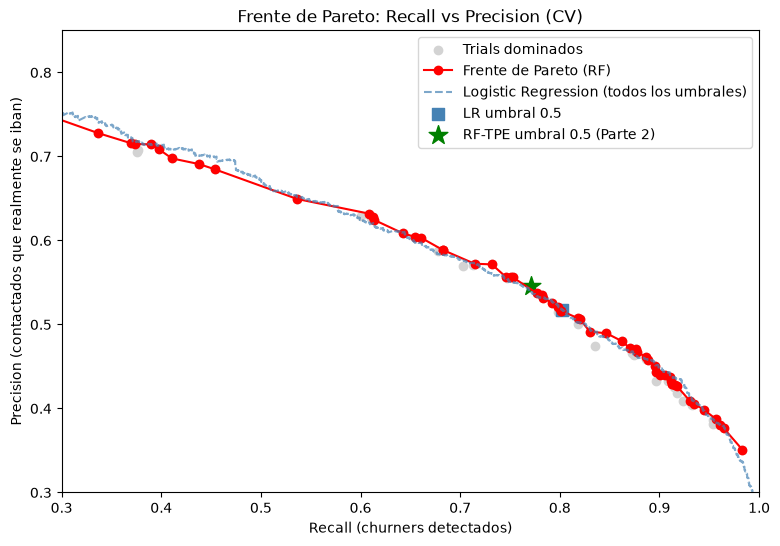

In [39]:
from sklearn.metrics import precision_recall_curve

lr_proba = cross_val_predict(models['Logistic Regression'], X_train, y_train, cv=cv,
                             method='predict_proba')[:, 1]
lr_prec, lr_rec, _ = precision_recall_curve(y_train, lr_proba)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(trials_df['recall'], trials_df['precision'], color='lightgray', label='Trials dominados')
ax.plot(pareto_df['recall'], pareto_df['precision'], 'o-', color='red', label='Frente de Pareto (RF)')
ax.plot(lr_rec, lr_prec, '--', color='steelblue', alpha=0.7, label='Logistic Regression (todos los umbrales)')
ax.scatter(lr['test_recall'].mean(), lr['test_precision'].mean(), marker='s', s=80, color='steelblue',
           label='LR umbral 0.5')
ax.scatter(opt_df.loc['TPE (Optuna)', 'Recall'], opt_df.loc['TPE (Optuna)', 'Precision'], marker='*',
           s=200, color='green', label='RF-TPE umbral 0.5 (Parte 2)')
ax.set_xlabel('Recall (churners detectados)')
ax.set_ylabel('Precision (contactados que realmente se iban)')
ax.set_title('Frente de Pareto: Recall vs Precision (CV)')
ax.set_xlim(0.3, 1.0)
ax.set_ylim(0.3, 0.85)
ax.legend()
plt.show()

### 5.5 Selección de una solución con criterio de negocio

Para elegir un punto del frente se estima el **valor neto de la campaña de retención** de cada solución.

> ⚠️ **Supuestos hipotéticos** (no son resultados del modelo; se declaran para ilustrar la decisión):
> - `COSTO_PROMO = 50 USD` por cliente contactado (≈ un descuento de 2–3 semanas de factura, considerando la mediana de 70 USD/mes).
> - `TASA_EXITO = 30 %`: proporción de churners contactados que acepta la promoción y se queda.
> - `MESES_RETENIDOS = 12`: meses de facturación que se conservan al retener a un cliente.

$$\text{Valor neto} = \sum_{i \in TP} \text{TASA\_EXITO} \cdot 12 \cdot \text{MonthlyCharges}_i \;-\; \text{COSTO\_PROMO} \cdot (TP + FP)$$

Los ingresos usan el `MonthlyCharges` **real** de cada cliente detectado; el costo se paga por **todos** los contactados, incluidas las falsas alarmas. Se calcula sobre las predicciones out-of-fold del train (5634 clientes).

**Regla de selección:** el valor neto forma una meseta amplia, así que no se elige el máximo absoluto sino la solución que **contacta a menos clientes conservando al menos el 95 % del valor neto máximo**. Motivos: capacidad operativa limitada del equipo de marketing, fatiga de los clientes por exceso de promociones y menor exposición si los supuestos son optimistas.

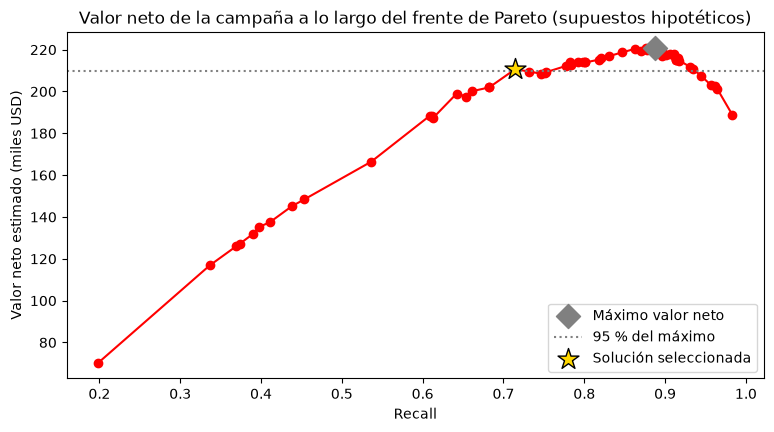

,trial,recall,precision,f1,threshold,% contactados,valor_neto
0,13,0.199,0.786,0.317,0.792,0.067,70309.98
1,60,0.336,0.728,0.460,0.792,0.123,116830.54
2,30,0.369,0.716,0.487,0.779,0.137,125980.08
3,74,0.374,0.715,0.491,0.779,0.139,127257.62
4,66,0.390,0.714,0.505,0.777,0.145,131869.68
5,25,0.397,0.709,0.509,0.745,0.149,135220.18
6,36,0.411,0.698,0.517,0.758,0.156,137428.30
7,71,0.438,0.691,0.536,0.745,0.168,145151.76
8,79,0.454,0.685,0.546,0.745,0.176,148400.64
9,48,0.536,0.649,0.588,0.663,0.219,166458.32


In [40]:
# SUPUESTOS HIPOTÉTICOS
COSTO_PROMO = 50
TASA_EXITO = 0.30
MESES_RETENIDOS = 12

monthly = X_train['MonthlyCharges'].to_numpy()
y_true = y_train.to_numpy()

def valor_neto(y_pred, costo=COSTO_PROMO, exito=TASA_EXITO):
    tp = (y_pred == 1) & (y_true == 1)
    return exito * MESES_RETENIDOS * monthly[tp].sum() - costo * y_pred.sum()

def pred_trial(row):
    return (oof_store[row['trial']] >= row['threshold']).astype(int)

pareto_df['% contactados'] = [pred_trial(r).mean() for _, r in pareto_df.iterrows()]
pareto_df['valor_neto'] = [valor_neto(pred_trial(r)) for _, r in pareto_df.iterrows()]
best_max = pareto_df.loc[pareto_df['valor_neto'].idxmax()]
candidatos = pareto_df[pareto_df['valor_neto'] >= 0.95 * best_max['valor_neto']]
best = candidatos.loc[candidatos['% contactados'].idxmin()]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pareto_df['recall'], pareto_df['valor_neto'] / 1000, 'o-', color='red')
ax.scatter(best_max['recall'], best_max['valor_neto'] / 1000, s=150, marker='D', color='gray',
           zorder=3, label='Máximo valor neto')
ax.axhline(0.95 * best_max['valor_neto'] / 1000, color='gray', linestyle=':', label='95 % del máximo')
ax.scatter(best['recall'], best['valor_neto'] / 1000, s=250, marker='*', color='gold', edgecolor='black',
           zorder=3, label='Solución seleccionada')
ax.set_xlabel('Recall')
ax.set_ylabel('Valor neto estimado (miles USD)')
ax.set_title('Valor neto de la campaña a lo largo del frente de Pareto (supuestos hipotéticos)')
ax.legend()
plt.show()

pareto_df[['trial', 'recall', 'precision', 'f1', 'threshold', '% contactados', 'valor_neto']].round(3)

### 5.6 Sensibilidad a los supuestos

Como los supuestos son hipotéticos, se comprueba cómo cambia la solución elegida si cambia el costo de la promoción o la tasa de éxito. Esto muestra **por qué el frente es útil**: distintos clientes (empresas) elegirán puntos distintos.

In [41]:
sens = []
for costo in [20, 50, 100, 150]:
    for exito in [0.15, 0.30, 0.50]:
        vals = [valor_neto(pred_trial(r), costo, exito) for _, r in pareto_df.iterrows()]
        r = pareto_df.iloc[int(np.argmax(vals))]
        sens.append({'costo_promo': costo, 'tasa_exito': exito, 'trial': int(r['trial']),
                     'threshold': round(r['threshold'], 3), 'recall': round(r['recall'], 3),
                     'precision': round(r['precision'], 3), '% contactados': round(r['% contactados'], 3),
                     'valor_neto': round(max(vals))})
pd.DataFrame(sens)

,costo_promo,tasa_exito,trial,threshold,recall,precision,% contactados,valor_neto
0,20,0.15,12,0.369,0.887,0.461,0.511,124845
1,20,0.30,53,0.204,0.965,0.376,0.680,316164
2,20,0.50,37,0.228,0.983,0.351,0.744,580022
3,50,0.15,64,0.622,0.642,0.609,0.280,60082
4,50,0.30,12,0.369,0.887,0.461,0.511,220910
5,50,0.50,27,0.355,0.911,0.437,0.553,466777
6,100,0.15,13,0.792,0.199,0.786,0.067,6805
7,100,0.30,64,0.622,0.642,0.609,0.280,120164
8,100,0.50,56,0.403,0.862,0.480,0.476,322494
9,150,0.15,13,0.792,0.199,0.786,0.067,-12095


In [42]:
trials_df.to_csv('artifacts/pareto_trials.csv', index=False)
pareto_df.to_csv('artifacts/pareto_front.csv', index=False)
selected = {'model': 'RandomForest',
            'params': {k: (int(best[k]) if k != 'max_features' else float(best[k]))
                       for k in ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']},
            'threshold': float(best['threshold']),
            'cv_recall': float(best['recall']), 'cv_precision': float(best['precision']), 'cv_f1': float(best['f1']),
            'supuestos': {'costo_promo': COSTO_PROMO, 'tasa_exito': TASA_EXITO, 'meses_retenidos': MESES_RETENIDOS}}
json.dump(selected, open('artifacts/selected_config.json', 'w'), indent=2)
selected

{'model': 'RandomForest',
 'params': {'n_estimators': 255,
  'max_depth': 7,
  'min_samples_leaf': 25,
  'max_features': 0.12200042998071398},
 'threshold': 0.5818462467582683,
 'cv_recall': 0.7143812709030101,
 'cv_precision': 0.572347266881029,
 'cv_f1': 0.635525141326986,
 'supuestos': {'costo_promo': 50, 'tasa_exito': 0.3, 'meses_retenidos': 12}}

### 5.7 Análisis del frente y decisión

**1. El umbral domina el frente.** 57 de las 80 soluciones son no dominadas y se ordenan casi perfectamente por el umbral τ (de 0.79 a 0.20). Los hiperparámetros del RF influyen poco, lo que es coherente con la Parte 2 (meseta de F1 ≈ 0.63–0.64). **La decisión relevante para el negocio no es el modelo, sino a cuántos clientes contactar.**

**2. Compromiso cuantificado.** En la zona media del frente, cada +10 puntos de recall cuestan ≈ 3–5 puntos de precision; en los extremos el costo se dispara: pasar de recall 0.89 a 0.98 hunde la precision de 0.46 a 0.35 y obliga a contactar al 74 % de la base.

**3. RF vs Regresión Logística.** La curva precision–recall de la LR (línea azul) prácticamente se superpone al frente del RF en todo el rango: **ambos modelos tienen el mismo poder de ordenar clientes por riesgo**. El RF-TPE de la Parte 2 y la LR con umbral 0.5 son simplemente dos puntos de esa misma curva.

**4. Solución seleccionada (regla del 95 %):** RF con `n_estimators=255, max_depth=7, min_samples_leaf=25, max_features≈0.12` y umbral **τ ≈ 0.58** → recall ≈ 0.71, precision ≈ 0.57, F1 ≈ 0.64, contactando al **≈ 33 %** de los clientes. Obtiene ≈ 95 % del valor neto máximo (≈ 211 k vs 221 k USD en el train) **contactando a un tercio menos de clientes** que la solución de máximo valor (51 %). Además es un RF poco profundo (7 niveles, hojas de ≥ 25 clientes): más rápido y más estable.

**5. Por qué otra solución puede ser mejor para otro cliente (sensibilidad):**
- Promoción barata (20 USD) y efectiva (50 %) → conviene contactar al 74 % (umbral 0.23).
- Promoción cara (150 USD) y poco efectiva (15 %) → incluso el punto más selectivo da **valor negativo**: la herramienta indica que **no conviene lanzar la campaña**.
- El frente se ofrece como un **"dial" de operación**: cada empresa elige el punto según el costo y la efectividad de sus promociones.

**6. Modelo final:** se elige el **Random Forest seleccionado** (con su umbral) porque: el desempeño es equivalente al de la LR; captura interacciones (p. ej. contrato × fibra) sin ingeniería manual; permite explicaciones SHAP exactas y rápidas (`TreeExplainer`) y la comparación con su feature importance exigida en la Parte 4. La LR se mantiene como **benchmark** en la app.

> Los valores monetarios dependen de supuestos hipotéticos y se calcularon sobre el train (out-of-fold); no son resultados reales del modelo.

## 6. Evaluación final en test

El modelo, sus hiperparámetros y el umbral ya están **decididos** (sección 5.7) usando solo el train. Ahora se entrena esa configuración con **todo el train** y se evalúa **una única vez** en el test (1409 clientes nunca vistos). Este resultado no se usa para cambiar ninguna decisión: es la estimación honesta del desempeño en producción.

La Regresión Logística (umbral 0.5) se evalúa también, solo como referencia para la app; no interviene en la selección.

In [43]:
import joblib
from sklearn.metrics import accuracy_score

THRESHOLD = selected['threshold']
final_model = make_rf(**selected['params'])
final_model.fit(X_train, y_train)

proba_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (proba_test >= THRESHOLD).astype(int)

print(f'Umbral de decisión: {THRESHOLD:.3f}\n')
print(classification_report(y_test, y_pred_test, target_names=['No churn', 'Churn'], digits=3))
print(f'ROC-AUC test: {roc_auc_score(y_test, proba_test):.3f}')

Umbral de decisión: 0.582

              precision    recall  f1-score   support

    No churn      0.886     0.792     0.836      1035
       Churn      0.555     0.717     0.625       374

    accuracy                          0.772      1409
   macro avg      0.720     0.754     0.731      1409
weighted avg      0.798     0.772     0.780      1409

ROC-AUC test: 0.843


In [44]:
def metricas(y_true_, y_pred_, proba_):
    return {'Accuracy': accuracy_score(y_true_, y_pred_), 'Precision': precision_score(y_true_, y_pred_),
            'Recall': recall_score(y_true_, y_pred_), 'F1': f1_score(y_true_, y_pred_),
            'ROC-AUC': roc_auc_score(y_true_, proba_)}

oof_sel = oof_store[int(best['trial'])]
lr_final = models['Logistic Regression'].fit(X_train, y_train)
lr_proba_test = lr_final.predict_proba(X_test)[:, 1]

comparacion = pd.DataFrame({
    'RF seleccionado - CV (train)': metricas(y_train, (oof_sel >= THRESHOLD).astype(int), oof_sel),
    'RF seleccionado - TEST': metricas(y_test, y_pred_test, proba_test),
    'LR benchmark - TEST': metricas(y_test, (lr_proba_test >= 0.5).astype(int), lr_proba_test),
}).T
comparacion.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
RF seleccionado - CV (train),0.783,0.572,0.714,0.636,0.847
RF seleccionado - TEST,0.772,0.555,0.717,0.625,0.843
LR benchmark - TEST,0.739,0.505,0.786,0.615,0.842


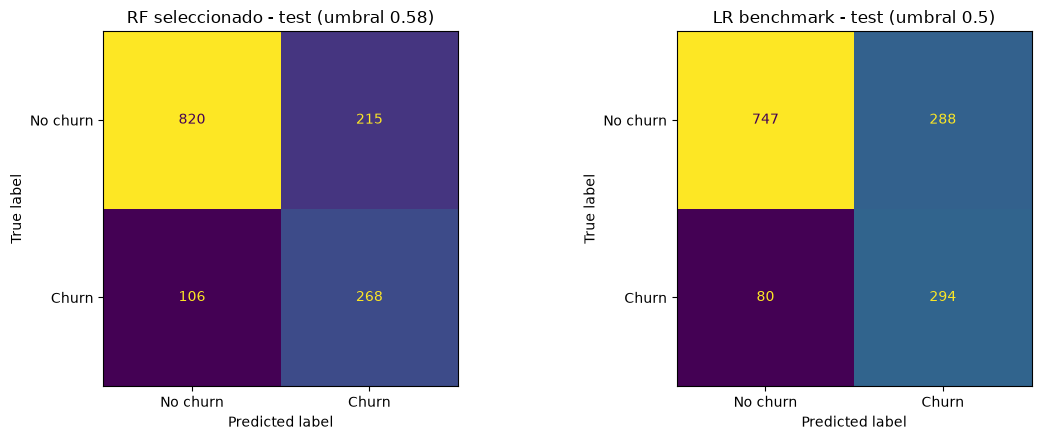

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, ax=axes[0], colorbar=False,
                                        display_labels=['No churn', 'Churn'])
axes[0].set_title(f'RF seleccionado - test (umbral {THRESHOLD:.2f})')
ConfusionMatrixDisplay.from_predictions(y_test, (lr_proba_test >= 0.5).astype(int), ax=axes[1],
                                        colorbar=False, display_labels=['No churn', 'Churn'])
axes[1].set_title('LR benchmark - test (umbral 0.5)')
plt.tight_layout()
plt.show()

### Interpretación de la evaluación final

**1. El modelo generaliza.** Test vs CV: recall 0.717 vs 0.714, precision 0.555 vs 0.572, F1 0.625 vs 0.636, ROC-AUC 0.843 vs 0.847. Las diferencias (≤ 0.017) son del orden de la variación entre folds y equivalen a unos pocos clientes en un test de 374 churners. No hay señales de sobreajuste ni de leakage. La leve caída en precision es esperable: la configuración se eligió entre 176 evaluadas, y la ganadora siempre conserva algo de suerte a su favor.

**2. Matriz de confusión (test, umbral 0.58), en lenguaje de negocio:**
- **268 TP:** churners detectados a tiempo → candidatos a la promoción.
- **106 FN:** churners que no se detectaron (28 %): el costo de no contactar a todos.
- **215 FP:** promociones a clientes que se iban a quedar (costo de la promoción, aunque refuerza su lealtad).
- **820 TN:** clientes que se quedan y no se molestan.
En total se contacta a **483 clientes (34 %)**, en línea con el 33 % previsto en la CV.

**3. RF vs Regresión Logística en test.** Mismo ROC-AUC (0.843 vs 0.842): confirman el empate en capacidad de ordenar. Con umbral 0.5 la LR contacta a más clientes (recall 0.786, precision 0.505); la diferencia en F1 se debe al umbral, no a que un modelo sea superior.

## 7. Explainable AI: SHAP, LIME y Feature Importance

La importancia de una variable se puede medir de varias formas, y cada una responde una pregunta distinta:

| Técnica | Pregunta que responde | Alcance |
|---|---|---|
| **Feature importance (MDI) del RF** | ¿Cuánto redujo la impureza (Gini) cada variable en las divisiones de los árboles, durante el entrenamiento? | Global |
| **Permutation importance** | ¿Cuánto empeora el modelo (ROC-AUC en test) si desordeno al azar una variable? | Global |
| **SHAP** | ¿Cuánto aportó cada variable a *esta* predicción respecto a la probabilidad media? (valores de Shapley, teoría de juegos) | Global y local |
| **LIME** | Si ajusto un modelo lineal simple alrededor de *este* cliente, ¿qué variables pesan más? | Local |

**Convenciones para interpretar correctamente:**
- Todas las explicaciones se refieren a la **clase churn = 1**: un valor positivo *empuja hacia el abandono*.
- El modelo trabaja con variables **transformadas** por el pipeline: las numéricas están estandarizadas y las categóricas en one-hot. Por ejemplo, `Contract_Two year = 1` significa "tiene contrato de 2 años". Para comparar técnicas se **agrupan las columnas one-hot por variable original** (sumando su aporte).
- **Importancia predictiva no implica causalidad:** que una variable pese en la predicción no significa que cambiarla cambie la decisión del cliente.

In [46]:
import shap
from lime.lime_tabular import LimeTabularExplainer

pre = final_model.named_steps['preprocess']
rf = final_model.named_steps['model_instance']

feat_names = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]
X_test_t = pd.DataFrame(pre.transform(X_test), columns=feat_names, index=X_test.index)

# Mapa: columna transformada -> variable original (para agrupar el one-hot)
def original_var(name):
    return next(c for c in num_columns + cat_columns if name == c or name.startswith(c + '_'))
var_of = {n: original_var(n) for n in feat_names}
print(len(feat_names), 'columnas transformadas ->', len(set(var_of.values())), 'variables originales')

26 columnas transformadas -> 19 variables originales


### 7.1 SHAP: explicación global

Se usa `TreeExplainer`, que calcula valores SHAP **exactos** para modelos de árboles. Para un Random Forest los valores están en unidades de **probabilidad**: predicción del cliente = valor base (probabilidad media) + suma de aportes de sus variables.

Valor base (probabilidad media de churn según el modelo): 0.500


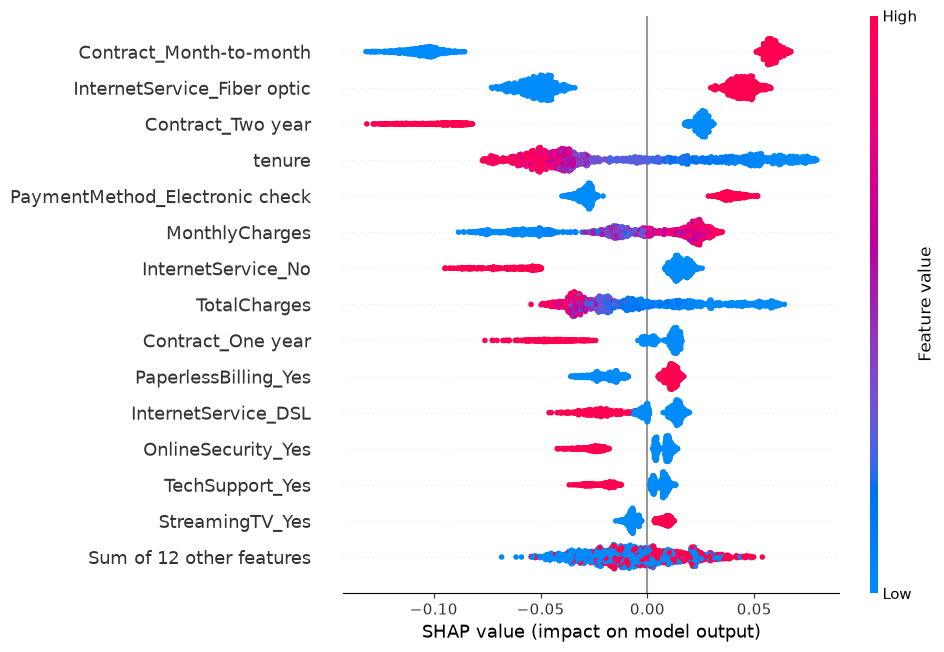

In [47]:
explainer = shap.TreeExplainer(rf)
sv = explainer(X_test_t)[:, :, 1]   # valores SHAP de la clase churn = 1
print(f'Valor base (probabilidad media de churn según el modelo): {sv.base_values[0]:.3f}')

# Verificación de aditividad: base + suma de aportes = probabilidad predicha
assert np.allclose(sv.base_values + sv.values.sum(axis=1), proba_test, atol=1e-6)

# Para los gráficos locales: mostrar las numéricas en su escala original (no estandarizada)
X_test_disp = X_test_t.copy()
X_test_disp[num_columns] = X_test[num_columns].values
sv.display_data = X_test_disp.values

shap.plots.beeswarm(sv, max_display=15)

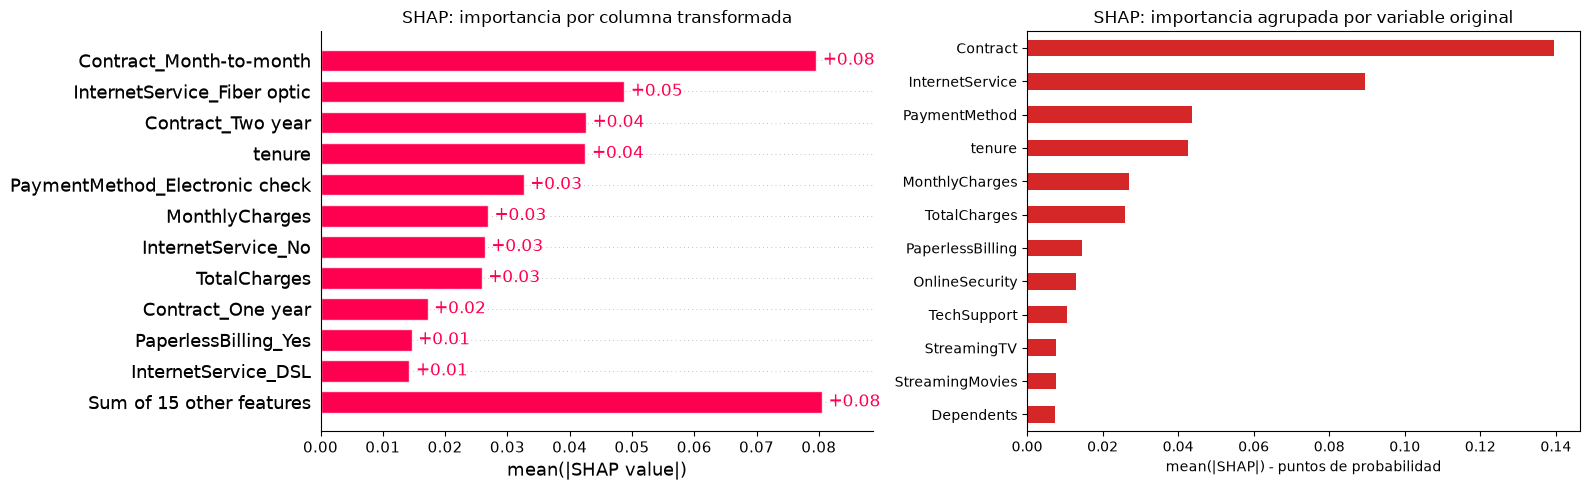

In [48]:
shap_global = (pd.DataFrame(np.abs(sv.values), columns=feat_names)
               .T.groupby(var_of).sum().T.mean()
               .sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
shap.plots.bar(sv, max_display=12, ax=axes[0], show=False)
axes[0].set_title('SHAP: importancia por columna transformada')
shap_global.head(12).sort_values().plot.barh(ax=axes[1], color='tab:red')
axes[1].set_title('SHAP: importancia agrupada por variable original')
axes[1].set_xlabel('mean(|SHAP|) - puntos de probabilidad')
plt.tight_layout()
plt.show()

### 7.2 Clientes a explicar

Se eligen dos clientes del test con criterio:
- **Cliente A — acierto de alto riesgo (TP):** el churner real con mayor probabilidad predicha. Representa el caso típico que marketing contactaría.
- **Cliente B — error del modelo (FN):** un churner real al que el modelo asignó baja probabilidad. Sirve para entender *por qué se equivoca* (pregunta clave del comprador).

In [49]:
cliente_A = X_test.index[np.argmax(np.where(y_test == 1, proba_test, -1))]
cliente_B = X_test.index[np.argmin(np.where(y_test == 1, proba_test, 2))]
clientes = {'A (TP alto riesgo)': cliente_A, 'B (FN)': cliente_B}

perfil = X_test.loc[[cliente_A, cliente_B]].T
perfil.columns = list(clientes)
perfil.loc['prob_churn'] = [proba_test[X_test.index.get_loc(i)].round(3) for i in clientes.values()]
perfil.loc['churn_real'] = [y_test.loc[i] for i in clientes.values()]
perfil

,A (TP alto riesgo),B (FN)
gender,Male,Female
SeniorCitizen,0,1
Partner,No,Yes
Dependents,No,Yes
tenure,1,72
PhoneService,Yes,Yes
MultipleLines,Yes,Yes
InternetService,Fiber optic,DSL
OnlineSecurity,No,Yes
OnlineBackup,No,Yes


### 7.3 SHAP: explicaciones locales

En el gráfico *waterfall* se parte del valor base E[f(x)] (abajo) y cada barra suma (rojo, hacia churn) o resta (azul, hacia quedarse) hasta llegar a la probabilidad del cliente f(x) (arriba).

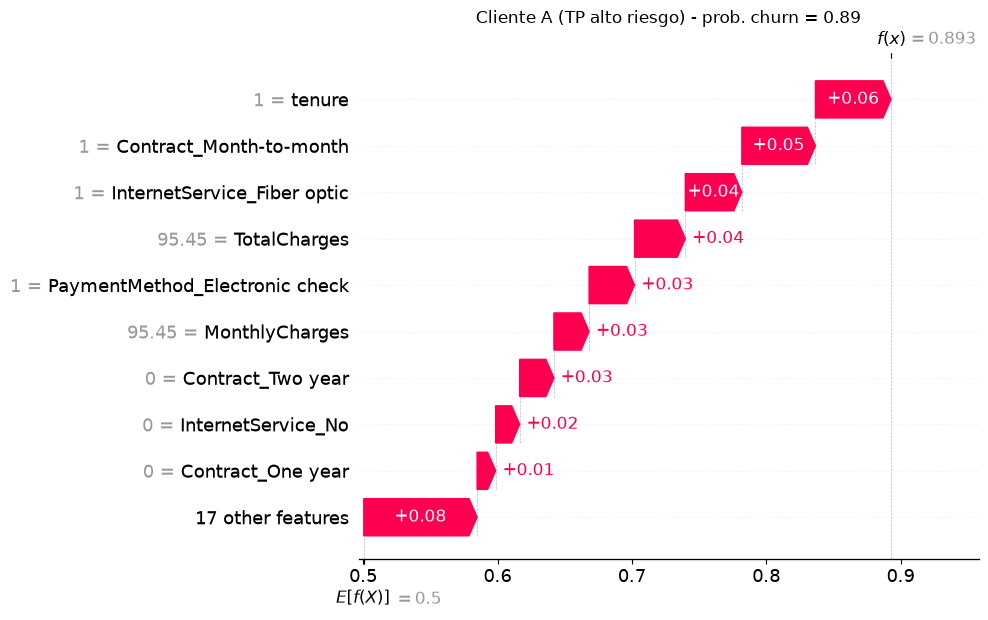

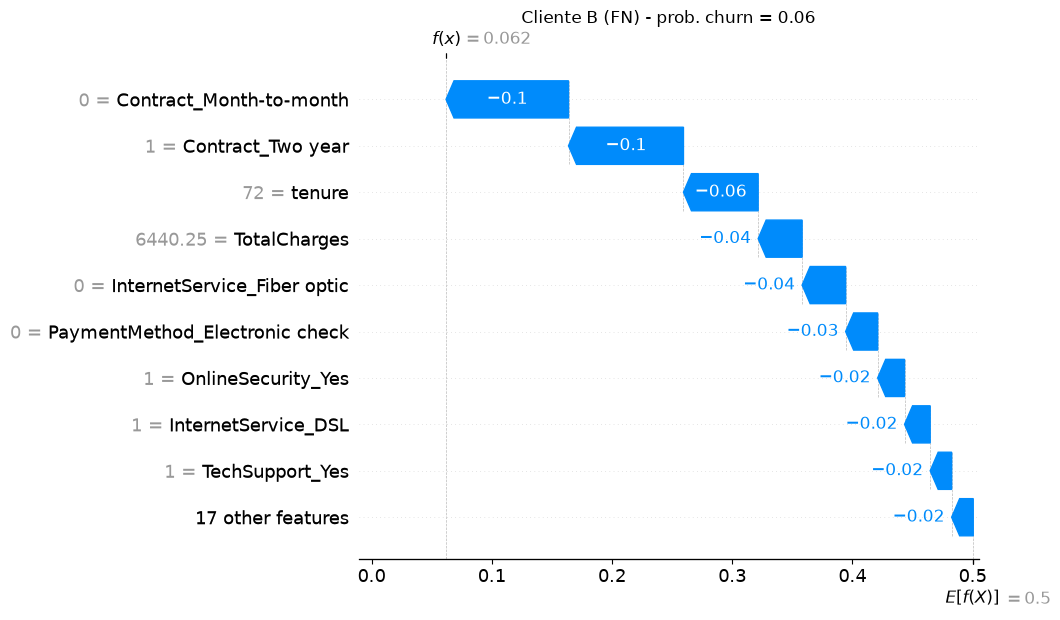

In [50]:
for nombre, idx in clientes.items():
    pos = X_test.index.get_loc(idx)
    plt.figure()
    shap.plots.waterfall(sv[pos], max_display=10, show=False)
    plt.title(f'Cliente {nombre} - prob. churn = {proba_test[pos]:.2f}')
    plt.show()

### 7.4 LIME: explicaciones locales de los mismos clientes

LIME genera miles de clientes "vecinos" perturbando al cliente original, obtiene la predicción del modelo para cada uno y ajusta un modelo lineal ponderado por cercanía. Los coeficientes de ese modelo lineal son la explicación.

Se aplica sobre las **variables originales** (no las transformadas) para que las reglas sean legibles (p. ej. `Contract=Month-to-month`, `tenure <= 9`): las categóricas se codifican como enteros solo para LIME y una función envoltorio las devuelve a texto antes de llamar al pipeline completo.

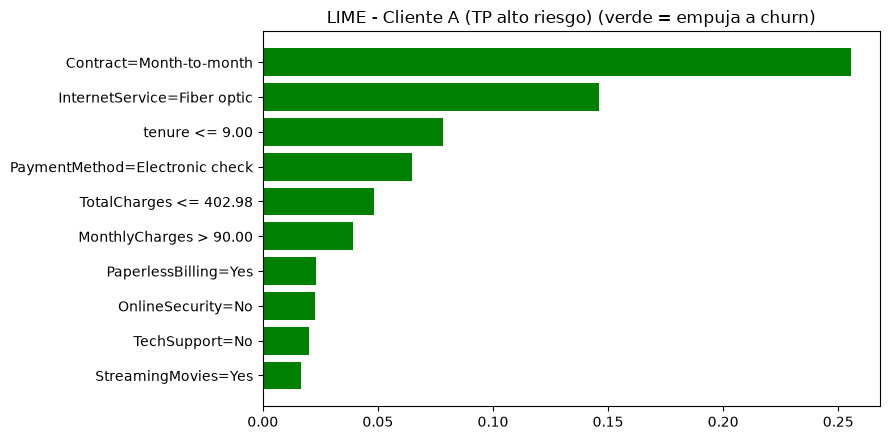

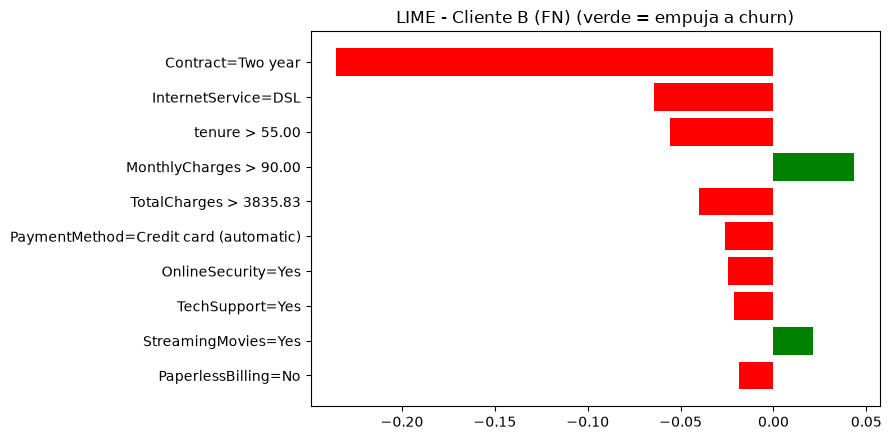

In [51]:
lime_cols = list(X_train.columns)
cat_vals = {c: sorted(X_train[c].astype(str).unique()) for c in cat_columns}

def lime_encode(df_):
    out = df_.copy()
    for c in cat_columns:
        out[c] = out[c].astype(str).map({v: i for i, v in enumerate(cat_vals[c])})
    return out.to_numpy(dtype=float)

def lime_predict(arr):
    d = pd.DataFrame(arr, columns=lime_cols)
    for c in cat_columns:
        d[c] = d[c].round().astype(int).map(dict(enumerate(cat_vals[c]))).astype(X_train[c].dtype)
    return final_model.predict_proba(d)

# Verificación: la envoltura reproduce exactamente las predicciones del pipeline
assert np.allclose(lime_predict(lime_encode(X_test))[:, 1], proba_test)

lime_explainer = LimeTabularExplainer(
    lime_encode(X_train), feature_names=lime_cols, class_names=['No churn', 'Churn'],
    categorical_features=[lime_cols.index(c) for c in cat_columns],
    categorical_names={lime_cols.index(c): cat_vals[c] for c in cat_columns},
    mode='classification', random_state=RANDOM_STATE)

lime_exps = {}
for nombre, idx in clientes.items():
    exp = lime_explainer.explain_instance(lime_encode(X_test.loc[[idx]])[0], lime_predict,
                                          num_features=10, labels=(1,), num_samples=5000)
    lime_exps[nombre] = exp
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(9, 4.5)
    plt.title(f'LIME - Cliente {nombre} (verde = empuja a churn)')
    plt.tight_layout()
    plt.show()

### 7.5 SHAP vs LIME en los mismos clientes

Se comparan las 5 variables originales con mayor aporte según cada técnica (SHAP agrupando el one-hot por variable original).

In [52]:
filas = []
for nombre, idx in clientes.items():
    pos = X_test.index.get_loc(idx)
    shap_local = pd.Series(sv.values[pos], index=feat_names).groupby(var_of).sum()
    shap_top = shap_local.reindex(shap_local.abs().sort_values(ascending=False).index).head(5)
    lime_top = lime_exps[nombre].as_list(label=1)[:5]
    for k in range(5):
        filas.append({'Cliente': nombre, 'Rank': k + 1,
                      'SHAP (variable: aporte)': f'{shap_top.index[k]}: {shap_top.iloc[k]:+.3f}',
                      'LIME (regla: peso)': f'{lime_top[k][0]}: {lime_top[k][1]:+.3f}'})
pd.DataFrame(filas).set_index(['Cliente', 'Rank'])

SHAP (variable: aporte)  \
Cliente            Rank                            
A (TP alto riesgo) 1            Contract: +0.094   
                   2     InternetService: +0.072   
                   3              tenure: +0.056   
                   4       PaymentMethod: +0.042   
                   5        TotalCharges: +0.038   
B (FN)             1            Contract: -0.200   
                   2              tenure: -0.062   
                   3     InternetService: -0.048   
                   4        TotalCharges: -0.037   
                   5       PaymentMethod: -0.034   

                                             LIME (regla: peso)  
Cliente            Rank                                          
A (TP alto riesgo) 1            Contract=Month-to-month: +0.255  
                   2        InternetService=Fiber optic: +0.146  
                   3                     tenure <= 9.00: +0.078  
                   4     PaymentMethod=Electronic check: +0.065  
                   5             TotalCharges <= 402.98: +0.048  
B (FN)             1                  Contract=Two year: -0.235  
                   2                InternetService=DSL: -0.064  
                   3                     tenure > 55.00: -0.056  
                   4             MonthlyCharges > 90.00: +0.043  
                   5             TotalCharges > 3835.83: -0.040

### 7.6 Comparación con Feature Importance del Random Forest y Permutation Importance

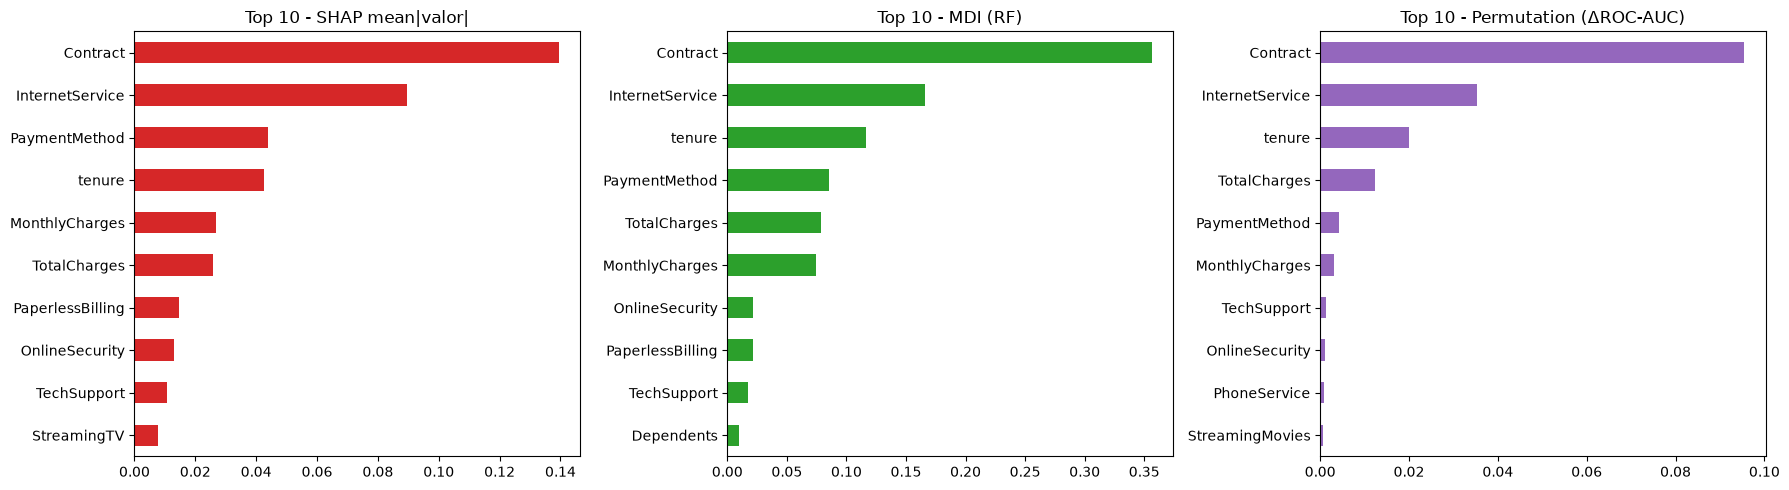

,SHAP mean|valor|,MDI (RF),Permutation (ΔROC-AUC),Rank SHAP mean|valor|,Rank MDI (RF),Rank Permutation (ΔROC-AUC)
Contract,0.1394,0.3561,0.0955,1,1,1
InternetService,0.0894,0.1658,0.0353,2,2,2
PaymentMethod,0.0438,0.0854,0.0043,3,4,5
tenure,0.0425,0.1164,0.0200,4,3,3
MonthlyCharges,0.0269,0.0746,0.0031,5,6,6
TotalCharges,0.0259,0.0784,0.0123,6,5,4
PaperlessBilling,0.0146,0.0214,0.0004,7,8,14
OnlineSecurity,0.0130,0.0214,0.0012,8,7,8
TechSupport,0.0105,0.0176,0.0013,9,9,7
StreamingTV,0.0077,0.0082,0.0006,10,12,12


In [53]:
from sklearn.inspection import permutation_importance

mdi = pd.Series(rf.feature_importances_, index=feat_names).groupby(var_of).sum()
perm = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns)

importancias = pd.DataFrame({'SHAP mean|valor|': shap_global, 'MDI (RF)': mdi,
                             'Permutation (ΔROC-AUC)': perm_imp})
ranks = importancias.rank(ascending=False).astype(int).add_prefix('Rank ')
tabla_imp = pd.concat([importancias.round(4), ranks], axis=1).sort_values('Rank SHAP mean|valor|')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color in zip(axes, importancias.columns, ['tab:red', 'tab:green', 'tab:purple']):
    importancias[col].sort_values().tail(10).plot.barh(ax=ax, color=color)
    ax.set_title(f'Top 10 - {col}')
plt.tight_layout()
plt.show()
tabla_imp.head(10)

In [54]:
importancias.to_csv('artifacts/feature_importance_comparison.csv')
X_train.sample(1000, random_state=RANDOM_STATE).to_csv('artifacts/X_train_sample.csv', index=False)

### 7.7 Análisis comparativo

**Nota sobre el valor base (0.50).** La probabilidad media que asigna el modelo es 0.50, aunque el churn real es 26.5 %. Se debe a `class_weight='balanced'`, que da el mismo peso total a ambas clases: las salidas del modelo son un **score de riesgo útil para ordenar clientes**, no una probabilidad calibrada. Por eso el umbral se eligió con criterio de negocio (0.58) y no se interpreta "0.89" como "89 % de probabilidad real".

**1. ¿Qué similitudes y diferencias hay entre SHAP y LIME?**
- **Similitudes:** para el cliente A coinciden en las 5 variables principales y casi en el mismo orden (Contract, InternetService, tenure, PaymentMethod, TotalCharges), todas empujando hacia churn. Para el cliente B coinciden en que el contrato de 2 años es, por lejos, lo que más lo aleja del churn, seguido de tenure e InternetService.
- **Diferencias:** SHAP es **exacto y aditivo** (base + aportes = predicción, verificado con `assert`) y da explicaciones globales y locales consistentes; LIME **aproxima** el modelo con una regresión lineal local, sus pesos no suman a la predicción y dependen del muestreo aleatorio y del ancho del vecindario. LIME expresa reglas legibles (`tenure <= 9`), SHAP aportes por variable. En el cliente B, LIME marca `MonthlyCharges > 90` como factor de riesgo (+0.043) que SHAP considera menor: LIME mira solo el vecindario inmediato del cliente.

**2. ¿Qué características resultaron relevantes?** Las tres técnicas globales coinciden en el **top 2: tipo de contrato e InternetService**, y en que el top 6 lo forman las mismas variables (Contract, InternetService, tenure, PaymentMethod, TotalCharges, MonthlyCharges). Siguen los servicios de protección (OnlineSecurity, TechSupport). `gender`, `DeviceProtection` y `PhoneService` prácticamente no aportan. Es coherente con el EDA.

**Comparación con la Feature Importance (MDI) del Random Forest:**
- Mismo top 2 que SHAP y permutación.
- MDI sube a `tenure` (3º) y `TotalCharges` (5º): el MDI tiene un **sesgo conocido a favor de variables numéricas continuas**, que ofrecen muchos puntos de corte posibles, y se calcula sobre el train (puede reflejar sobreajuste).
- Permutation importance (medida en test) baja a `PaymentMethod` (5º) y `PaperlessBilling` (14º): al desordenarlas el modelo compensa con otras variables correlacionadas, por lo que su aporte es en parte **redundante**.
- `tenure` y `TotalCharges` (correlación 0.83) se reparten el mérito: sumadas (SHAP 0.068) quedarían como el tercer bloque más importante, cerca de InternetService.

**3. ¿Cómo se explica una predicción a una persona sin conocimientos técnicos?**
- *Cliente A (riesgo 0.89, sí abandonó):* "Este cliente lleva **un mes** con nosotros, tiene **contrato mes a mes**, **fibra óptica sin soporte técnico ni seguridad** y paga con **cheque electrónico**. Cada uno de esos rasgos es frecuente entre los clientes que se van, y en él se juntan todos. Sugerencia: ofrecerle pasar a un contrato anual con descuento o soporte técnico incluido."
- *Cliente B (riesgo 0.06, sí abandonó):* "Para el modelo era un cliente muy leal: **6 años** con nosotros, **contrato de 2 años**, todos los servicios contratados y pago automático. Se fue por algo que **no está en los datos** (una mudanza, una oferta de la competencia, una mala experiencia). Ningún modelo puede detectar lo que no observa: por eso conviene sumar datos de reclamos y uso del servicio."

**4. ¿Qué limitaciones presentan ambas técnicas?**
- **SHAP:** reparte el mérito entre variables correlacionadas (tenure/TotalCharges) y puede evaluar combinaciones irreales; para modelos no basados en árboles es lento (KernelExplainer); explica **al modelo, no a la realidad**.
- **LIME:** inestable (otra semilla o número de muestras puede cambiar el orden); la definición del vecindario y la discretización (`tenure <= 9`) son arbitrarias; la aproximación lineal puede ser mala si el modelo es muy no lineal; genera clientes sintéticos que pueden ser irreales (p. ej. 1 mes de antigüedad con 6000 USD facturados).
- **Ambas:** explican correlaciones aprendidas por el modelo, **no causas**.

**5. Importancia predictiva ≠ causalidad.** Que `PaymentMethod = Electronic check` empuje hacia churn no significa que cambiar a pago automático retenga al cliente: puede ser un indicador de un perfil menos comprometido. Igual con el contrato: quien firma 2 años ya es un cliente comprometido (autoselección); obligar a contratos largos no garantiza retención. Estas hipótesis deben validarse con experimentos (A/B) antes de convertirlas en política comercial.

## 8. Ranking de clientes por riesgo
Una empresa normalmente no puede ofrecer incentivos a todos sus clientes. Utilice la probabilidad de `Churn=1` para construir un ranking de riesgo.

**Escenario:** suponga que el área comercial solo puede intervenir sobre el **10% de los clientes del conjunto de evaluación con mayor riesgo estimado**.


In [55]:
ids = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')['customerID']

ranking = pd.DataFrame({'customerID': ids.loc[X_test.index].values,
                        'prob_churn': proba_test,
                        'churn_real': y_test.values,
                        'MonthlyCharges': X_test['MonthlyCharges'].values,
                        'Contract': X_test['Contract'].values,
                        'tenure': X_test['tenure'].values})
ranking = ranking.sort_values('prob_churn', ascending=False).reset_index(drop=True)
top10 = ranking.head(int(0.10 * len(ranking)))
print(f'Top 10 %: {len(top10)} clientes | churn real en el grupo: {top10["churn_real"].mean():.1%} '
      f'(tasa base: {y_test.mean():.1%})')
top10.head(15)

Top 10 %: 140 clientes | churn real en el grupo: 74.3% (tasa base: 26.5%)


,customerID,prob_churn,churn_real,MonthlyCharges,Contract,tenure
0,0295-PPHDO,0.892845,1,95.45,Month-to-month,1
1,1069-XAIEM,0.886541,1,85.05,Month-to-month,1
2,5178-LMXOP,0.885217,1,95.10,Month-to-month,1
3,9248-OJYKK,0.880678,1,76.45,Month-to-month,1
4,0970-ETWGE,0.879901,1,89.55,Month-to-month,1
5,3722-WPXTK,0.879529,1,88.35,Month-to-month,1
6,2514-GINMM,0.877549,1,79.50,Month-to-month,1
7,9057-SIHCH,0.875899,1,96.60,Month-to-month,3
8,2609-IAICY,0.874352,1,77.15,Month-to-month,1
9,4415-IJZTP,0.874015,1,74.50,Month-to-month,1


### Lift: cuánto mejor que contactar al azar

Si el equipo de marketing contacta al k % de clientes con mayor riesgo, ¿qué proporción realmente se iba (precision) y qué parte de todos los churners captura (recall)? El **lift** compara esa precision con la tasa base (lo que se obtendría eligiendo clientes al azar).

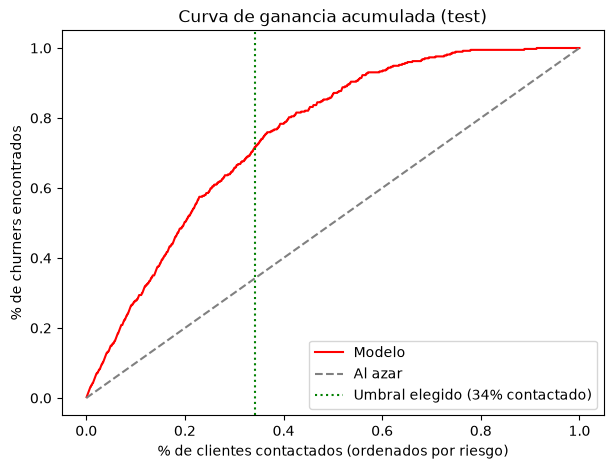

,% contactado,clientes,churners encontrados,precision,recall,lift
0,5%,70,56,0.800,0.150,3.01
1,10%,140,104,0.743,0.278,2.80
2,20%,281,188,0.669,0.503,2.52
3,30%,422,245,0.581,0.655,2.19
4,40%,563,293,0.520,0.783,1.96
5,50%,704,324,0.460,0.866,1.73


In [56]:
base = y_test.mean()
lift_rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    grupo = ranking.head(int(k * len(ranking)))
    prec = grupo['churn_real'].mean()
    lift_rows.append({'% contactado': f'{k:.0%}', 'clientes': len(grupo),
                      'churners encontrados': int(grupo['churn_real'].sum()),
                      'precision': round(prec, 3),
                      'recall': round(grupo['churn_real'].sum() / y_test.sum(), 3),
                      'lift': round(prec / base, 2)})
lift_df = pd.DataFrame(lift_rows)

pct = np.arange(1, len(ranking) + 1) / len(ranking)
ganancia = ranking['churn_real'].cumsum() / ranking['churn_real'].sum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pct, ganancia, color='red', label='Modelo')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Al azar')
ax.axvline(y_pred_test.mean(), color='green', linestyle=':', label=f'Umbral elegido ({y_pred_test.mean():.0%} contactado)')
ax.set_xlabel('% de clientes contactados (ordenados por riesgo)')
ax.set_ylabel('% de churners encontrados')
ax.set_title('Curva de ganancia acumulada (test)')
ax.legend()
plt.show()
lift_df

In [57]:
# Valor neto en test con los MISMOS supuestos hipotéticos de la sección 5.5
def valor_test(contactados):
    tp = contactados & (y_test.to_numpy() == 1)
    return TASA_EXITO * MESES_RETENIDOS * X_test['MonthlyCharges'].to_numpy()[tp].sum() - COSTO_PROMO * contactados.sum()

n_contact = int(y_pred_test.sum())
rng = np.random.default_rng(RANDOM_STATE)
azar = np.zeros(len(y_test), dtype=bool)
azar[rng.choice(len(y_test), n_contact, replace=False)] = True

escenarios = pd.DataFrame({
    'Estrategia': ['Modelo (umbral elegido)', f'Al azar ({n_contact} clientes)', 'Contactar a todos'],
    'Contactados': [n_contact, n_contact, len(y_test)],
    'Valor neto (USD, hipotético)': [valor_test(y_pred_test.astype(bool)), valor_test(azar),
                                     valor_test(np.ones(len(y_test), dtype=bool))],
})
escenarios.round(0)

,Estrategia,Contactados,"Valor neto (USD, hipotético)"
0,Modelo (umbral elegido),483,50189.0
1,Al azar (483 clientes),483,8694.0
2,Contactar a todos,1409,27524.0


### Interpretación del ranking y del valor

- **Top 10 % (140 clientes): 74.3 % realmente abandona**, frente al 26.5 % al azar → **lift 2.8×**. En lenguaje de marketing: *de cada 4 llamadas, 3 son a clientes que estaban por irse*. El top 5 % llega a 80 % (lift 3.0×).
- El perfil del top del ranking coincide con el EDA: contrato mes a mes, 1–3 meses de antigüedad y cargos altos (fibra).
- **Curva de ganancia:** contactando al 34 % (umbral elegido) se encuentra al **72 %** de los churners; al azar se encontraría al 34 %.
- **Valor neto en test (supuestos hipotéticos de la sección 5.5):** el modelo genera ≈ **50 k USD** frente a ≈ 9 k USD contactando al mismo número de clientes al azar (**5.8×**) y ≈ 28 k USD contactando a todos. El modelo no solo acierta más: **cambia la decisión económica**, porque contactar a todos cuesta más de lo que recupera en los clientes que no se iban a ir.

> Los valores en USD dependen de supuestos (costo 50 USD, éxito 30 %, 12 meses) y se calcularon sobre 1409 clientes de test. El lift, el recall y la precision sí son resultados del modelo.

**Limitaciones:** un único split de test (incertidumbre de ±0.02–0.03 en las métricas); datos de un solo momento (en producción hay que monitorear y reentrenar); el modelo predice abandono, no el efecto de la promoción (validar con un piloto A/B); entrenado con datos de esta empresa (otra empresa requiere reentrenar con sus datos).

In [58]:
from sklearn.metrics import confusion_matrix
os.makedirs('models', exist_ok=True)
joblib.dump(final_model, 'models/rf_final.joblib')
joblib.dump(lr_final, 'models/lr_benchmark.joblib')

results_df.to_csv('artifacts/model_comparison_cv.csv')
comparacion.to_csv('artifacts/test_metrics.csv')
lift_df.to_csv('artifacts/lift_test.csv', index=False)
test_clients = X_test.assign(Churn=y_test.values)
test_clients.insert(0, 'customerID', ids.loc[X_test.index].values)
test_clients.to_csv('artifacts/test_clients.csv', index=False)  # demo de la app
pd.DataFrame(confusion_matrix(y_test, y_pred_test), index=['real_0', 'real_1'],
             columns=['pred_0', 'pred_1']).to_csv('artifacts/confusion_matrix_test.csv')

# Verificación: el modelo cargado desde archivo predice lo mismo
assert np.allclose(joblib.load('models/rf_final.joblib').predict_proba(X_test)[:, 1], proba_test)
print('Modelos exportados:', os.listdir('models'))

Modelos exportados: ['lr_benchmark.joblib', 'rf_final.joblib']


## 9. Propuesta de negocio: Clien↩urn

### 9.1 Del modelo a la decisión: hallazgos para el negocio

**1. Perfiles de mayor riesgo.** Clientes con **contrato mes a mes**, **en su primer año** (especialmente los primeros 3 meses), con **fibra óptica sin servicios de soporte o seguridad** y que pagan con **cheque electrónico**. El segmento mes a mes + fibra llega a 55 % de churn (EDA), y el top 10 % del ranking tiene exactamente este perfil.

**2. Características más relevantes para la predicción.** Tipo de contrato e InternetService (top 2 en SHAP, MDI y permutación), seguidos de antigüedad (`tenure`), método de pago y cargos (`MonthlyCharges`, `TotalCharges`). `gender` no aporta.

**3. Acciones de retención** (cada una ligada al factor que SHAP señala en el cliente):

| Factor de riesgo del cliente (SHAP) | Acción sugerida |
|---|---|
| Contrato mes a mes | Descuento por migrar a contrato anual |
| Fibra sin TechSupport / OnlineSecurity | 3 meses de soporte técnico o seguridad sin costo |
| Antigüedad ≤ 12 meses | Programa de bienvenida: contacto proactivo a los 30, 60 y 90 días |
| Cargo mensual alto | Revisión de plan: ajustar a un paquete con mejor relación precio/servicios |
| Pago con cheque electrónico | Incentivo por domiciliar el pago (hipótesis a validar, no causal) |

**4. Métrica a priorizar.** Para **elegir el modelo**, F1 y ROC-AUC (capacidad de ordenar). Para **operar**, la decisión se toma sobre el frente recall–precision eligiendo el umbral que maximiza el **valor neto** de la campaña: el recall indica cuántos churners se rescatan y la precision cuánto presupuesto se desperdicia.

**5. Costo de un falso negativo.** Un churner no detectado es un cliente perdido: con la mediana de cargo de los churners (79.65 USD/mes), ≈ **956 USD de facturación anual**. Un falso positivo cuesta solo la promoción (50 USD, supuesto). Esta asimetría (≈ 19:1) justifica privilegiar el recall frente al umbral 0.5.

**6. Si el presupuesto solo alcanza para el 10 %.** Se contacta a los clientes del **top 10 % del ranking**: en test, 74.3 % de ellos realmente abandonaba (lift 2.8× frente al azar), capturando al 28 % de todos los churners. Dentro de ese grupo, el orden de llamada sigue el score de riesgo y la promoción se elige según su factor SHAP principal.

**7. Limitaciones al convertir importancia en acción.** La importancia es **predictiva, no causal**: que el pago con cheque electrónico se asocie al churn no garantiza que cambiarlo retenga al cliente (puede indicar un perfil menos comprometido). Lo mismo con el contrato (autoselección: quien firma 2 años ya estaba comprometido). Además, variables correlacionadas reparten su importancia. Toda acción debe validarse con un **grupo de control (A/B)** antes de escalarla.

### 9.2 Clien↩urn — *antes de que crucen la puerta*

> **Clien↩urn** (client + return): la flecha que da la vuelta representa al cliente que iba hacia la salida y regresa.

**1. Problema u oportunidad.** Los **operadores regionales de internet y cable** pierden una proporción alta de clientes (en el dataset analizado, 1 de cada 4 en el periodo) y compiten contra grandes operadores con más presupuesto. A diferencia de estos, **no tienen equipos de ciencia de datos**: sus campañas de retención son reactivas (llaman cuando el cliente ya pidió la baja) o generalistas (descuentos a todos, o reglas simples como "todos los mes a mes"). Para un operador pequeño, cada cliente perdido pesa más en sus ingresos.

**2. Producto.** Plataforma de **retención predictiva** para equipos comerciales y de marketing que responde cuatro preguntas cada mes:
- **¿A quién contactar?** Ranking de clientes por riesgo de abandono.
- **¿A cuántos?** Un "dial" de operación (frente de Pareto) que ajusta el umbral al presupuesto disponible.
- **¿Por qué está en riesgo y qué ofrecerle?** Explicación individual (SHAP/LIME) traducida a lenguaje simple y a una acción de retención sugerida.
- **¿Cuánto vale hacerlo?** Simulador de valor neto según el costo y la efectividad de la promoción, que también indica **cuándo no conviene lanzar una campaña**.

**3. Comprador.** El **gerente comercial o de marketing** de un operador regional de internet y cable con 5.000–50.000 clientes, que tiene presupuesto de retención limitado y necesita justificar cada gasto ante la gerencia general.

**4. Propuesta de valor.** *"Concentra tu presupuesto de retención donde realmente rinde."* En los 1.409 clientes de prueba (nunca vistos por el modelo):
- Contactando al **10 %** que señala Clien↩urn, **3 de cada 4** realmente estaban por irse (lift 2.8×).
- Contactando al **34 %** (punto de operación elegido), se encuentra al **72 %** de los clientes que se van.
- Cada predicción viene con su explicación: no es una caja negra.

**5. Cómo el Machine Learning genera valor.**
- El **Random Forest** optimizado ordena a los clientes por riesgo (ROC-AUC 0.84 en test, sin sobreajuste).
- La **optimización multiobjetivo (NSGA-II)** convierte el modelo en un menú de puntos de operación: el cliente elige según su presupuesto y sus costos reales.
- **SHAP y LIME** explican cada cliente y alimentan el motor de acciones sugeridas (tabla 9.1).
- El **reentrenamiento trimestral** mantiene el modelo vigente ante cambios de precios, competencia o comportamiento.

**6. Por qué elegir Clien↩urn frente a alternativas.**

| Alternativa | Limitación | Clien↩urn |
|---|---|---|
| No hacer nada / reaccionar a la baja | El cliente ya decidió irse | Detecta el riesgo antes |
| Reglas manuales ("todos los mes a mes") | Contacta al 55 % con 43 % de precision; no ordena ni explica | Con el mismo presupuesto, más churners detectados y menos falsas alarmas; cada cliente con su razón |
| CRM empresariales con IA | Costosos, genéricos, pensados para grandes empresas | Entrenado con los datos del operador, a precio de operador regional |
| Contratar un científico de datos | Costo fijo alto para una empresa pequeña | Servicio completo (modelo + mantenimiento + app) por una fracción |

**7. Modelo de ingresos y justificación económica** *(precios y valores hipotéticos)*.

Modelo **híbrido**:

| Etapa | Qué incluye | Precio |
|---|---|---|
| **1. Piloto** (3 meses) | Modelo entrenado con sus datos + campaña con **grupo de control** para medir la retención real | 1.500 USD |
| **2. Implementación** | Integración de datos, entrenamiento, validación, configuración de la app | 3.000 USD (pago único) |
| **3. Suscripción** | App, ranking mensual, explicaciones, **reentrenamiento trimestral** y monitoreo | 800 USD/mes (hasta 15.000 clientes) |

Costo para el operador el primer año: 1.500 + 3.000 + 9 × 800 = **11.700 USD**; desde el segundo año, 9.600 USD/año.

Valor neto estimado para un operador de **10.000 clientes** (escalando los resultados del modelo con los supuestos de la sección 5.5):

| Escenario | Costo promoción | Tasa de éxito | Valor neto anual estimado | Retorno sobre 11.700 USD |
|---|---|---|---|---|
| Pesimista | 50 USD | 15 % | ≈ 107.000 USD | ≈ 9× |
| **Base (test)** | 50 USD | 30 % | **≈ 356.000 USD** | **≈ 30×** |
| Base con supuestos inflados 5 veces | — | — | ≈ 71.000 USD | ≈ 6× |
| Promoción cara e inefectiva | 150 USD | 15 % | negativo | La herramienta recomienda **no** lanzar la campaña |

**Costos propios estimados (hipotéticos):** infraestructura ≈ 30 USD/mes por operador; reentrenamiento ≈ 16 h por trimestre; soporte ≈ 4 h/mes → ≈ 265 USD/mes frente a 800 USD de suscripción (margen ≈ 67 %).

> ⚠️ Los valores monetarios **no son resultados del modelo**: dependen de supuestos (costo de promoción, tasa de aceptación, 12 meses de retención) que el **piloto con grupo de control** permite reemplazar por datos reales del operador. Lo que sí proviene del modelo son el ranking, el lift, el recall y la precision.

**8. Limitaciones, riesgos y desafíos.**
- **Datos:** el modelo debe reentrenarse con los datos de cada operador; un operador con poco historial o datos desordenados requiere más trabajo de implementación.
- **Errores del modelo:** ≈ 28 % de los churners no se detecta en el punto de operación elegido; algunos se van por causas que los datos no capturan (cliente B: mudanza, oferta de la competencia). Mitigación: **encuesta de salida** para descubrir qué nuevas señales medir (tickets de soporte, cortes de servicio, cambios de tarifa), usada como diagnóstico y nunca como variable predictiva (sería data leakage).
- **Deriva (drift):** el comportamiento de los clientes cambia; por eso el reentrenamiento trimestral está incluido en la suscripción.
- **Efectividad de la promoción:** el modelo predice quién se va, no si la promoción lo retiene; se mide en el piloto.
- **Costos ocultos:** promociones a clientes que se iban a quedar (falsos positivos) y fatiga por exceso de contactos; por eso se opera en el 34 % y no contactando a todos.
- **Privacidad y ética:** uso de datos personales sujeto a la normativa de protección de datos; variables como la edad (`SeniorCitizen`) deben revisarse para evitar tratos discriminatorios.
- **Causalidad:** las explicaciones muestran asociaciones, no causas; las acciones sugeridas son hipótesis a validar.

## 10. Entregable
Entregue el `.ipynb` convertido a formato PDF.

### Checklist
- [ ] Auditoría y preparación.
- [ ] Pipeline sin leakage.
- [ ] Al menos dos modelos comparados.
- [ ] CV y optimización.
- [ ] Test usado solo al final.
- [ ] Top 5–10 características relevantes.
- [ ] Ranking de clientes por probabilidad.
- [ ] Propuesta de negocio respaldada por resultados.
- [ ] Discusión de feature importance ≠ causalidad.
